# QBC13 · تحلیل داده و پیش‌پردازش دیجی‌کالا

این نوت‌بوک، بخش EDA از `01_eda_fixed.ipynb` و خط پردازش کامل `02_cleaning_repo_based.ipynb` را در یک اجرا ترکیب می‌کند.

۱. **ورودی و تنظیمات** مسیر داده و بسته‌های موردنیاز را آماده می‌کند.
۲. **بخش A · EDA** کیفیت دادهٔ خام، توزیع‌ها و رابطهٔ محصولات و نظرات را بررسی می‌کند و `eda_summary.json` می‌سازد.
۳. **بخش B · پیش‌پردازش** کاتالوگ و نظرات پاک، آمار، پیکرهٔ RAG و تقسیم‌های آموزش مدل را می‌سازد و کنترل می‌کند.

در Jupyter این فایل را کنار `digikala-products.csv` و `digikala-comments.csv` بگذار و **Run All** بزن. مسیرهای `data` و `data/raw` هم به‌صورت خودکار بررسی می‌شوند. اگر داده جای دیگری است، `DATA_DIR` را در سلول تنظیمات روی پوشهٔ واقعی بگذار. اگر Parquet خام از قبل موجود باشد، همان خوانده می‌شود.

**خروجی‌ها:** `processed_repo_based` در پوشهٔ داده. فایل‌های موقت در همان درایو ساخته و پس از اجرای موفق پاک می‌شوند. برای اجرای کامل حدود ۱۰ گیگابایت فضای خالی در نظر بگیر. پردازش روی CPU انجام می‌شود و پاک‌سازی همهٔ نظرات ممکن است چند دقیقه طول بکشد.

بخش EDA از نوت‌بوک اولیهٔ هم‌تیمی و بخش پاک‌سازی با الهام از [مخزن مصباح، کامیت ffacf9c](https://github.com/mmz1380/QBC_AI12_G2_P3/tree/ffacf9cb79f5902a54ec88059b1772c184f3a0c5) تهیه شده‌اند.

نمودارها و اعداد نمایش‌داده‌شده مربوط به اجرای مرجع با دو CSV اصلی‌اند. با اجرای مجدد، خروجی‌ها روی دستگاه خودت نوشته می‌شوند.

## ورودی و تنظیمات

سلول بعد فقط بسته‌هایی را نصب می‌کند که در محیط همین کرنل موجود نیستند. در صورت خطای نصب، خروجی همان سلول علت را نشان می‌دهد.

In [1]:
from importlib.util import find_spec
import subprocess
import sys

dependencies = {
    "duckdb": "duckdb==1.5.0",
    "persiantools": "persiantools==5.5.1",
    "polars": "polars==1.39.3",
    "matplotlib": "matplotlib==3.10.8",
    "numpy": "numpy",
}
missing_packages = [package for module, package in dependencies.items() if find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

In [2]:
import ast
import html
import json
import os
import re
import unicodedata
from pathlib import Path
from tempfile import TemporaryDirectory

import duckdb
from persiantools.jdatetime import JalaliDate

# None یعنی پوشهٔ نوت‌بوک، data و data/raw به‌ترتیب بررسی شوند.
DATA_DIR = None
# None یعنی پوشهٔ processed_repo_based در همان مسیر داده.
OUTPUT_DIR = None
REQUIRE_FULL_DATASET = True
# اگر واحد را از منبع معتبر تأیید کردید، rial یا toman بگذارید.
PRICE_UNIT = None
MEMORY_LIMIT = "2GB"
THREADS = 4

SEED = 42
TRAIN_PCT, VALIDATION_PCT = 80, 10
# مقدار None سقف را برمی‌دارد؛ اعتبارسنجی و آزمون به نسبت کلاس‌ها دست نمی‌زنند.
TRAIN_MAX_PER_CLASS = 60_000
EVAL_MAX_PER_SPLIT = 15_000
# مقدار None تمام نظراتِ مناسبِ بازیابی را وارد فهرست می‌کند.
RAG_MAX_PER_PRODUCT = 48
RAG_STARTER_SIZE = 15_000
RAG_STARTER_REVIEWS_PER_PRODUCT = 24
RAG_STARTER_MIN_REVIEWS = 10
LABELS = ("recommended", "not_recommended", "no_idea")
SOURCE_REVISION = "89c3133b169c8d3793db8834f56f32fee33d9db0"

REFERENCE_COMMIT = "ffacf9cb79f5902a54ec88059b1772c184f3a0c5"
EXPECTED_RAW_ROWS = {"products": 1_283_496, "comments": 6_156_289}

### قواعد مشترک متن و شناسه

نرمال‌سازی اولیه HTML را باز می‌کند، Unicode NFKC را اعمال می‌کند و چند شکل ی/ک و ارقام را یکی می‌کند. کلمات منفی، ایموجی و نیم‌فاصله در متن مدل حفظ می‌شوند. در نسخهٔ واژگانی، نشانه‌گذاری و نیم‌فاصله به مرز توکن تبدیل می‌شوند. تابع `lexical_text` را برای پرسش BM25 هم استفاده کن. متن خام برای ارجاع جدا نگه داشته می‌شود.

In [3]:
def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"


INPUT_FILE_PAIRS = (
    ("products_raw.parquet", "digikala-products.csv"),
    ("comments_raw.parquet", "digikala-comments.csv"),
)


def has_inputs(directory):
    return all(any((directory / name).is_file() for name in alternatives)
               for alternatives in INPUT_FILE_PAIRS)


if DATA_DIR is None:
    folders = [Path("."), Path("digikala"), Path("data"), Path("data/raw"), Path("../digikala"), Path("../data"), Path("../data/raw")]
    data_root = next((p.resolve() for p in folders if has_inputs(p)), None)
    if data_root is None:
        options = ", ".join(str(p.resolve()) for p in folders)
        raise FileNotFoundError(
            f"هر دو فایل محصول و نظر را در یک پوشه بگذار یا DATA_DIR را تنظیم کن. {options}"
        )
else:
    data_root = Path(DATA_DIR).expanduser().resolve()
output_root = (data_root / "processed_repo_based" if OUTPUT_DIR is None
               else Path(OUTPUT_DIR).expanduser().resolve())
print("مسیر ورودی:", data_root, "| خروجی:", output_root)


def source(parquet_name, csv_name):
    parquet_path, csv_path = data_root / parquet_name, data_root / csv_name
    if parquet_path.is_file():
        return parquet_path, f"read_parquet({sql_string(parquet_path.as_posix())})"
    if csv_path.is_file():
        return csv_path, (
            f"read_csv({sql_string(csv_path.as_posix())}, "
            "header=true, all_varchar=true, delim=',', quote='\"', escape='\"', parallel=false)"
        )
    raise FileNotFoundError(f"فایل {parquet_path} یا {csv_path} را در مسیر ورودی قرار بده.")


products_path, products_source = source("products_raw.parquet", "digikala-products.csv")
comments_path, comments_source = source("comments_raw.parquet", "digikala-comments.csv")
if PRICE_UNIT not in (None, "rial", "toman"):
    raise ValueError("PRICE_UNIT باید None، rial یا toman باشد.")
if not 0 < TRAIN_PCT < 100 or not 0 < VALIDATION_PCT < 100 - TRAIN_PCT:
    raise ValueError("هر سه سهم train / validation / test باید مثبت باشند.")
for limit in (TRAIN_MAX_PER_CLASS, EVAL_MAX_PER_SPLIT, RAG_MAX_PER_PRODUCT):
    if limit is not None and (type(limit) is not int or limit < 1):
        raise ValueError("سقف باید عدد صحیح مثبت یا None باشد.")

if any(type(n) is not int or n < 1 for n in
       (RAG_STARTER_SIZE, RAG_STARTER_REVIEWS_PER_PRODUCT, RAG_STARTER_MIN_REVIEWS)):
    raise ValueError("تنظیم‌های اندازهٔ نمونهٔ RAG باید عدد صحیح مثبت باشند.")
if RAG_STARTER_MIN_REVIEWS > min(RAG_STARTER_REVIEWS_PER_PRODUCT, RAG_MAX_PER_PRODUCT or float("inf")):
    raise ValueError("حداقل نظر برای نمونهٔ RAG از سقف نظر هر محصول بیشتر است.")

if "con" in globals():
    con.close()
if "work" in globals():
    work.cleanup()
output_root.mkdir(parents=True, exist_ok=True)
work = TemporaryDirectory(prefix=".cleaning_", dir=output_root)
staging = Path(work.name).resolve()
con = duckdb.connect(str(staging / "working.duckdb"))
con.execute(f"SET memory_limit = {sql_string(MEMORY_LIMIT)}")
con.execute("SET threads = ?", [THREADS])
con.execute("SET preserve_insertion_order = false")
con.execute(f"SET temp_directory = {sql_string((staging / 'spill').as_posix())}")
con.execute(f"CREATE VIEW raw_products AS SELECT * FROM {products_source}")
con.execute(f"CREATE VIEW raw_comments AS SELECT * FROM {comments_source}")


def count(table, predicate="TRUE"):
    return con.sql(f"SELECT count(*) FROM {table} WHERE {predicate}").fetchone()[0]


def records(query):
    result = con.sql(query)
    keys = result.columns
    return [dict(zip(keys, row)) for row in result.fetchall()]


report = {
    "duckdb_version": duckdb.__version__,
    "eda_report": "eda_summary.json",
    "expected_source_revision": SOURCE_REVISION,
    "reference_preprocessing_commit": REFERENCE_COMMIT,
    "inputs": {
        "products": {"filename": products_path.name, "rows": count("raw_products")},
        "comments": {"filename": comments_path.name, "rows": count("raw_comments")},
    },
    "settings": {
        "seed": SEED, "price_unit": PRICE_UNIT,
        "target_split_pct": {
            "train": TRAIN_PCT,
            "validation": VALIDATION_PCT,
            "test": 100 - TRAIN_PCT - VALIDATION_PCT,
        },
        "train_max_per_class": TRAIN_MAX_PER_CLASS,
        "eval_max_per_split": EVAL_MAX_PER_SPLIT,
        "rag_max_per_product": RAG_MAX_PER_PRODUCT,
        "require_full_dataset": REQUIRE_FULL_DATASET,
        "rag_starter_size": RAG_STARTER_SIZE,
        "rag_starter_reviews_per_product": RAG_STARTER_REVIEWS_PER_PRODUCT,
        "rag_starter_min_reviews": RAG_STARTER_MIN_REVIEWS,
    },
}

CHAR_MAP = str.maketrans("يىك٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "ییک01234567890123456789")
WEB_MARKUP = re.compile(r"https?://\S+|www\.\S+|</?[a-z][^>]*>", re.IGNORECASE)
REMOVE_CHARS = re.compile(r"[ـ\u064b-\u065f\u0670\u200e\u200f\u202a-\u202e\u2066-\u2069\ufeff]")
LEXICAL_TOKEN = re.compile(r"[^\W_]+")
NULL_TEXT = {"", "none", "nan", "null", "n/a", "-"}
JALALI_MONTH = dict(zip(
    "فروردین اردیبهشت خرداد تیر مرداد شهریور مهر آبان آذر دی بهمن اسفند".split(),
    range(1, 13),
))


def normalize_persian_text(value):
    if value is None:
        return None
    if "&" in value:
        value = html.unescape(value)
    value = unicodedata.normalize("NFKC", value).translate(CHAR_MAP)
    value = WEB_MARKUP.sub(" ", value)
    value = REMOVE_CHARS.sub("", value)
    value = " ".join(value.replace("\u200b", " ").split())
    return value if value.lower() not in NULL_TEXT else None


def lexical_text(value):
    normalized = normalize_persian_text(value)
    if normalized is None:
        return None
    return " ".join(LEXICAL_TOKEN.findall(normalized.lower())) or None


def aspect_text(value):
    if value is None:
        return None
    value = value.strip()
    parts = [value]
    if value.startswith("[") and value.endswith("]"):
        try:
            items = ast.literal_eval(value)
        except (ValueError, SyntaxError, RecursionError):
            # Preserve malformed source text when the list cannot be parsed.
            items = None
        if isinstance(items, list):
            parts = [item for item in items if isinstance(item, str)]
    normalized = [normalize_persian_text(item) for item in parts]
    return " ؛ ".join(dict.fromkeys(item for item in normalized if item)) or None


def jalali_to_date(value):
    parts = (normalize_persian_text(value) or "").split()
    if len(parts) != 3 or parts[1] not in JALALI_MONTH:
        return None
    day, month, year = parts
    try:
        return JalaliDate(int(year), JALALI_MONTH[month], int(day)).to_gregorian()
    except (TypeError, ValueError, OverflowError):
        return None


for name, function, return_type in (
    ("persian_text", normalize_persian_text, "VARCHAR"),
    ("lexical_text", lexical_text, "VARCHAR"),
    ("aspect_text", aspect_text, "VARCHAR"),
    ("jalali_to_date", jalali_to_date, "DATE"),
):
    con.create_function(name, function, ["VARCHAR"], return_type, null_handling="special")


if REQUIRE_FULL_DATASET:
    observed = {name: meta["rows"] for name, meta in report["inputs"].items()}
    if observed != EXPECTED_RAW_ROWS:
        raise ValueError(f"تعداد ردیف‌های ورودی با نسخهٔ پروژه یکی نیست. ورودی: {observed}")

con.execute(r'''
    CREATE MACRO missing(x) AS
        CASE WHEN lower(trim(CAST(x AS VARCHAR))) IN ('', 'nan', 'null', 'none', 'n/a', '-')
             THEN NULL ELSE trim(CAST(x AS VARCHAR)) END;
    CREATE MACRO unify_chars(x) AS
        translate(nfc_normalize(x), 'يىك٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹', 'ییک01234567890123456789');
    CREATE MACRO normalize_fa(x) AS persian_text(missing(x));
    CREATE MACRO review_core(title, body) AS
        nullif(concat_ws(' . ', title, CASE WHEN body IS DISTINCT FROM title THEN body END), '');
    CREATE MACRO review_chars(x) AS regexp_replace(lower(x), '[^\p{L}\p{N}\p{So}]', '', 'g');
    CREATE MACRO review_hash(x) AS md5(nullif(review_chars(x), ''));
    CREATE MACRO clean_number(x) AS try_cast(unify_chars(missing(x)) AS DOUBLE);
    CREATE MACRO whole_nonnegative(x) AS
        CASE WHEN isfinite(x) AND x >= 0 AND floor(x) = x THEN try_cast(x AS BIGINT) END;
    CREATE MACRO clean_bool(x) AS CASE
        WHEN lower(missing(x)) IN ('true', '1') THEN TRUE
        WHEN lower(missing(x)) IN ('false', '0') THEN FALSE END;
    CREATE MACRO clean_label(x) AS CASE
        WHEN lower(missing(x)) IN ('recommended', 'not_recommended', 'no_idea')
        THEN lower(missing(x)) END;
''')
print("ورودی‌ها:", report["inputs"])

مسیر ورودی: C:\Users\fateme shakiba\Desktop\pro3\data | خروجی: C:\Users\fateme shakiba\Desktop\pro3\data\processed_repo_based
ورودی‌ها: {'products': {'filename': 'digikala-products.csv', 'rows': 1283496}, 'comments': {'filename': 'digikala-comments.csv', 'rows': 6156289}}


## بخش A · تحلیل اکتشافی دادهٔ خام

CSV با همان تنظیم سخت‌گیرانه و ترتیبی که در خط پاک‌سازی استفاده می‌شود خوانده می‌شود. برای جلوگیری از خواندن چندبارهٔ CSV، جدول خام موقت Parquet ساخته و میان دو بخش به اشتراک گذاشته می‌شود. این مرحله محتوای خام را پاک یا فیلتر نمی‌کند. اگر ورودی Parquet باشد، کپی موقت لازم نیست.

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

plt.rcParams["figure.dpi"] = 110
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(90)

def raw_parquet_for_analysis(path, relation, name):
    if path.suffix.lower() == ".parquet":
        return path
    cached = staging / name
    if not cached.is_file():
        partial = cached.with_suffix(".part")
        partial.unlink(missing_ok=True)
        con.execute(
            f"COPY (SELECT * FROM {relation}) TO {sql_string(partial.as_posix())} "
            "(FORMAT PARQUET, COMPRESSION ZSTD)"
        )
        os.replace(partial, cached)
    con.execute(
        f"CREATE OR REPLACE VIEW {relation} AS "
        f"SELECT * FROM read_parquet({sql_string(cached.as_posix())})"
    )
    return cached

p_raw = pl.scan_parquet(raw_parquet_for_analysis(products_path, "raw_products", "eda_products_raw.parquet"))
c_raw = pl.scan_parquet(raw_parquet_for_analysis(comments_path, "raw_comments", "eda_comments_raw.parquet"))
STATS = {}

p_cols = p_raw.collect_schema().names()
c_cols = c_raw.collect_schema().names()
print("products columns:", p_cols)
print("comments columns:", c_cols)

def find_col(cols, pattern):
    hits = [c for c in cols if re.search(pattern, c, flags=re.I)]
    if not hits:
        raise KeyError(f"column like {pattern!r} not found in {cols}")
    return hits[0]

# نگاشت نام ستون‌ها (نام‌ها در داده‌ی واقعی با PDF کمی فرق دارد)
PC = dict(
    id=find_col(p_cols, r"^id$"),
    title=find_col(p_cols, r"(fa_title|title_fa)"),
    rate=find_col(p_cols, r"^rate$"),
    cnt=find_col(p_cols, r"(cnt.*rate|rate.*cnt)"),
    cat1=find_col(p_cols, r"category.*1"),
    cat2=find_col(p_cols, r"category.*2"),
    brand=find_col(p_cols, r"^brand$"),
    price=find_col(p_cols, r"^price$"),
    seller=find_col(p_cols, r"^seller$"),
    fake=find_col(p_cols, r"fake"),
    mlp=find_col(p_cols, r"(month_last_price|min_price_last_month)"),
    catsub=find_col(p_cols, r"(category_sub|sub_category)"),
)
CC = dict(
    id=find_col(c_cols, r"^id$"),
    title=find_col(c_cols, r"^title$"),
    body=find_col(c_cols, r"^body$"),
    at=find_col(c_cols, r"(at_created|created_at)"),
    rate=find_col(c_cols, r"^rate$"),
    status=find_col(c_cols, r"(status_recommendation|recommendation_status)"),
    buyer=find_col(c_cols, r"(buyer_is|is_buyer)"),
    pid=find_col(c_cols, r"(id_product|product_id)"),
    adv=find_col(c_cols, r"^advantage"),
    dis=find_col(c_cols, r"^disadvantage"),
    likes=find_col(c_cols, r"^likes$"),
    dislikes=find_col(c_cols, r"^dislikes$"),
    seller=find_col(c_cols, r"(title_seller|seller_title)"),
    scode=find_col(c_cols, r"(code_seller|seller_code)"),
    size=find_col(c_cols, r"size"),
)
print(PC); print(CC)

products columns: ['id', 'title_fa', 'Rate', 'Rate_cnt', 'Category1', 'Category2', 'Brand', 'Price', 'Seller', 'Is_Fake', 'min_price_last_month', 'sub_category']
comments columns: ['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']
{'id': 'id', 'title': 'title_fa', 'rate': 'Rate', 'cnt': 'Rate_cnt', 'cat1': 'Category1', 'cat2': 'Category2', 'brand': 'Brand', 'price': 'Price', 'seller': 'Seller', 'fake': 'Is_Fake', 'mlp': 'min_price_last_month', 'catsub': 'sub_category'}
{'id': 'id', 'title': 'title', 'body': 'body', 'at': 'created_at', 'rate': 'rate', 'status': 'recommendation_status', 'buyer': 'is_buyer', 'pid': 'product_id', 'adv': 'advantages', 'dis': 'disadvantages', 'likes': 'likes', 'dislikes': 'dislikes', 'seller': 'seller_title', 'scode': 'seller_code', 'size': 'true_to_size_rate'}


In [5]:
# گزارش مقدارهای گمشده: null، رشته‌ی خالی، و رشته‌هایی مثل nan/null/none
MISSING_TOKENS = ["nan", "null", "none", "n/a", "-"]

def null_report(lf):
    cols = lf.collect_schema().names()
    exprs = []
    for c in cols:
        s = pl.col(c).cast(pl.Utf8).str.strip_chars()
        exprs.append((s.is_null() | (s == "") | s.str.to_lowercase().is_in(MISSING_TOKENS)).sum().alias(c))
    row = lf.select(exprs).collect().row(0)
    n = lf.select(pl.len()).collect().item()
    return pl.DataFrame({"column": cols, "missing": list(row),
                         "pct": [round(v / n * 100, 2) for v in row]}).sort("pct", descending=True)

N_PRODUCTS_RAW = p_raw.select(pl.len()).collect().item()
N_COMMENTS_RAW = c_raw.select(pl.len()).collect().item()
STATS["n_products_raw"] = N_PRODUCTS_RAW
STATS["n_comments_raw"] = N_COMMENTS_RAW
print(f"products: {N_PRODUCTS_RAW:,} | comments: {N_COMMENTS_RAW:,}")

products: 1,283,496 | comments: 6,156,289


### ۲. EDA جدول محصولات

In [6]:
rep = null_report(p_raw)
STATS["products_missing_pct"] = dict(zip(rep["column"], rep["pct"]))
rep

column,missing,pct
str,i64,f64
"""Category2""",210108,16.37
"""Seller""",223,0.02
"""id""",0,0.0
"""title_fa""",0,0.0
"""Rate""",0,0.0
"""Rate_cnt""",0,0.0
"""Category1""",0,0.0
"""Brand""",0,0.0
"""Price""",0,0.0


In [7]:
# تبدیل نوع ستون‌های عددی + شمارش مقدارهای غیرقابل‌تبدیل
num_p = [PC["rate"], PC["cnt"], PC["price"], PC["mlp"]]

bad = p_raw.select([
    (pl.col(c).is_not_null() & (pl.col(c).str.strip_chars() != "") &
     pl.col(c).cast(pl.Float64, strict=False).is_null()).sum().alias(c)
    for c in num_p
]).collect()
print("مقدارهای غیرقابل‌تبدیل به عدد:")
print(bad)

products = p_raw.with_columns([pl.col(c).cast(pl.Float64, strict=False) for c in num_p])
products.select(num_p).describe()

مقدارهای غیرقابل‌تبدیل به عدد:
shape: (1, 4)
┌──────┬──────────┬───────┬──────────────────────┐
│ Rate ┆ Rate_cnt ┆ Price ┆ min_price_last_month │
│ ---  ┆ ---      ┆ ---   ┆ ---                  │
│ u32  ┆ u32      ┆ u32   ┆ u32                  │
╞══════╪══════════╪═══════╪══════════════════════╡
│ 0    ┆ 0        ┆ 0     ┆ 0                    │
└──────┴──────────┴───────┴──────────────────────┘


statistic,Rate,Rate_cnt,Price,min_price_last_month
str,f64,f64,f64,f64
"""count""",1.283496e6,1.283496e6,1.283496e6,1.283496e6
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",30.13031,20.738292,8.4913e6,421214.718359
"""std""",39.910976,218.210075,4.6632e7,1.2025e7
"""min""",0.0,0.0,0.0,0.0
"""25%""",0.0,0.0,700000.0,0.0
"""50%""",0.0,0.0,1.56e6,0.0
"""75%""",80.0,2.0,4.45e6,0.0
"""max""",100.0,30438.0,8.5000e9,7.6455e9


In [8]:
# شناسه‌ی تکراری و ردیف‌های کاملاً تکراری
n = N_PRODUCTS_RAW
n_unique_id = products.select(pl.col(PC["id"]).n_unique()).collect().item()
n_unique_rows = count('''(SELECT DISTINCT * REPLACE (
    clean_number(Rate) AS Rate, clean_number(Rate_cnt) AS Rate_cnt,
    clean_number(Price) AS Price, clean_number(min_price_last_month) AS min_price_last_month
) FROM raw_products)''')
print(f"سطرها: {n:,} | id یکتا: {n_unique_id:,} | سطر کاملاً یکتا: {n_unique_rows:,}")
STATS["products_dup_ids"] = n - n_unique_id
STATS["products_full_dup_rows"] = n - n_unique_rows

dup_ids = (products.group_by(PC["id"]).len().filter(pl.col("len") > 1)
           .sort("len", descending=True).head(10).collect())
dup_ids

سطرها: 1,283,496 | id یکتا: 948,352 | سطر کاملاً یکتا: 960,367


id,len
str,u32
"""2577295""",11
"""2569919""",10
"""2577200""",10
"""2577471""",10
"""4426409""",9
"""2577503""",9
"""4278054""",9
"""6897295""",9
"""2585276""",9


null: 0 | <=0: 223 | >0: 1283273
shape: (11, 2)
┌───────┬───────────┐
│ q     ┆ price     │
│ ---   ┆ ---       │
│ f64   ┆ f64       │
╞═══════╪═══════════╡
│ 0.0   ┆ 20000.0   │
│ 0.001 ┆ 127500.0  │
│ 0.01  ┆ 180000.0  │
│ 0.05  ┆ 300000.0  │
│ 0.25  ┆ 700000.0  │
│ 0.5   ┆ 1.56e6    │
│ 0.75  ┆ 4.4518e6  │
│ 0.95  ┆ 3.30662e7 │
│ 0.99  ┆ 1.1e8     │
│ 0.999 ┆ 5.5e8     │
│ 1.0   ┆ 8.5000e9  │
└───────┴───────────┘


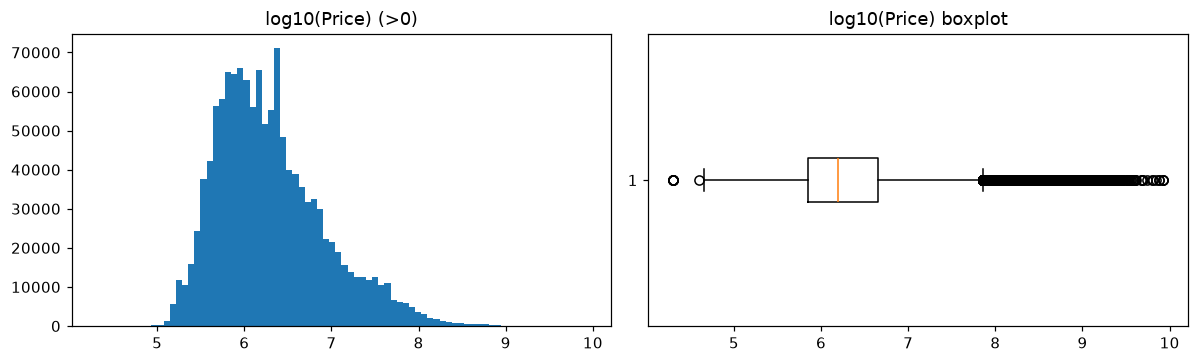

In [9]:
# قیمت: صفر/منفی، توزیع و دم سنگین
price = PC["price"]
pr = products.select(pl.col(price)).collect()[price]
print("null:", pr.null_count(), "| <=0:", (pr <= 0).sum(), "| >0:", (pr > 0).sum())
qs = [0.0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1.0]
print(pl.DataFrame({"q": qs, "price": [float(pr.filter(pr > 0).quantile(q)) for q in qs]}))

pos = pr.filter(pr > 0).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(np.log10(pos), bins=80); ax[0].set_title("log10(Price) (>0)")
from inspect import signature

if "orientation" in signature(ax[1].boxplot).parameters:
    ax[1].boxplot(np.log10(pos), orientation="horizontal")
else:
    ax[1].boxplot(np.log10(pos), vert=False)
ax[1].set_title("log10(Price) boxplot")
plt.tight_layout(); plt.show()

# دادهٔ خام واحد قیمت را همراه هر ردیف مشخص نمی‌کند.
STATS["price_zero_or_neg"] = int((pr <= 0).sum())
STATS["price_median"] = float(pr.filter(pr > 0).median())

> **توجه:** ستون `min_price_last_month` در ~۹۴٪ ردیف‌ها صفر است (یعنی ثبت نشده)، پس در پروژه از آن استفاده نمی‌کنیم.

Rate خارج از [0,100]: 0
Rate صفر یا null (بدون امتیاز): 799172
cnt_Rate منفی: 0
ناسازگار: cnt=0 ولی Rate>0 : 0
ناسازگار: cnt>0 ولی Rate==0: 21


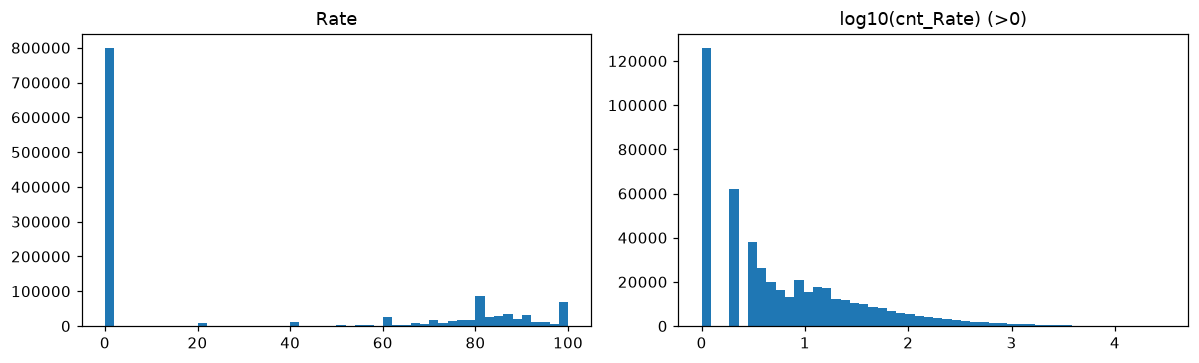

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1.283496e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 20.738292  │
│ std        ┆ 218.210075 │
│ min        ┆ 0.0        │
│ 25%        ┆ 0.0        │
│ 50%        ┆ 0.0        │
│ 75%        ┆ 2.0        │
│ max        ┆ 30438.0    │
└────────────┴────────────┘


In [10]:
# امتیاز و تعداد امتیاز
rate, cnt = PC["rate"], PC["cnt"]
rt = products.select([pl.col(rate), pl.col(cnt)]).collect()
print("Rate خارج از [0,100]:", rt.filter((pl.col(rate) < 0) | (pl.col(rate) > 100)).height)
print("Rate صفر یا null (بدون امتیاز):", rt.filter(pl.col(rate).is_null() | (pl.col(rate) == 0)).height)
print("cnt_Rate منفی:", rt.filter(pl.col(cnt) < 0).height)
print("ناسازگار: cnt=0 ولی Rate>0 :", rt.filter((pl.col(cnt) == 0) & (pl.col(rate) > 0)).height)
print("ناسازگار: cnt>0 ولی Rate==0:", rt.filter((pl.col(cnt) > 0) & (pl.col(rate) == 0)).height)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(rt[rate].drop_nulls().to_numpy(), bins=50); ax[0].set_title("Rate")
ax[1].hist(np.log10(rt[cnt].drop_nulls().filter(rt[cnt].drop_nulls() > 0).to_numpy()), bins=50)
ax[1].set_title("log10(cnt_Rate) (>0)")
plt.tight_layout(); plt.show()
print(rt[cnt].describe())

In [11]:
# دسته‌بندی، برند، فروشنده، Fake_Is
def top(lf, col, k=20):
    return (lf.group_by(col).len().sort("len", descending=True).head(k).collect()
              .with_columns((pl.col("len") / N_PRODUCTS_RAW * 100).round(2).alias("pct")))

for key in ["cat1", "cat2", "catsub", "fake"]:
    col = PC[key]
    n_u = products.select(pl.col(col).n_unique()).collect().item()
    print(f"\n=== {col}  (یکتا: {n_u:,}) ===")
    print(top(products, col, 15))

n_brand = products.select(pl.col(PC["brand"]).n_unique()).collect().item()
n_seller = products.select(pl.col(PC["seller"]).n_unique()).collect().item()
print(f"\nبرندهای یکتا: {n_brand:,} | فروشنده‌های یکتا: {n_seller:,}")
print(top(products, PC["brand"], 15))


=== Category1  (یکتا: 228) ===
shape: (15, 3)
┌────────────────────────┬───────┬──────┐
│ Category1              ┆ len   ┆ pct  │
│ ---                    ┆ ---   ┆ ---  │
│ str                    ┆ u32   ┆ f64  │
╞════════════════════════╪═══════╪══════╡
│ اکسسوری زنانه و مردانه ┆ 95999 ┆ 7.48 │
│ لباس زنانه             ┆ 93392 ┆ 7.28 │
│ اسباب بازی             ┆ 92466 ┆ 7.2  │
│ لباس مردانه            ┆ 68178 ┆ 5.31 │
│ اکسسوری زنانه          ┆ 64470 ┆ 5.02 │
│ اکسسوری مردانه         ┆ 49383 ┆ 3.85 │
│ دخترانه                ┆ 42931 ┆ 3.34 │
│ دفتر و کاغذ و مقوا     ┆ 42864 ┆ 3.34 │
│ زیورآلات طلا زنانه       ┆ 41098 ┆ 3.2  │
│ کتاب چاپی غیر فارسی    ┆ 39409 ┆ 3.07 │
│ مراقبت پوست            ┆ 29662 ┆ 2.31 │
│ مواد غذایی             ┆ 28930 ┆ 2.25 │
│ پسرانه                 ┆ 27066 ┆ 2.11 │
│ کتاب شعر و ادبیات      ┆ 23345 ┆ 1.82 │
│ برس‌ها و تجهیزات آرایشی ┆ 22749 ┆ 1.77 │
└────────────────────────┴───────┴──────┘

=== Category2  (یکتا: 602) ===
shape: (15, 3)
┌────────────────────

In [12]:
# طول عنوان محصول
t = PC["title"]
tl = products.select(pl.col(t).str.len_chars().alias("L")).collect()["L"]
print(tl.describe())

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1.283496e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 42.283272  │
│ std        ┆ 16.989205  │
│ min        ┆ 7.0        │
│ 25%        ┆ 30.0       │
│ 50%        ┆ 40.0       │
│ 75%        ┆ 50.0       │
│ max        ┆ 198.0      │
└────────────┴────────────┘


### ۳. EDA جدول نظرات

In [13]:
rep = null_report(c_raw)
STATS["comments_missing_pct"] = dict(zip(rep["column"], rep["pct"]))
rep

column,missing,pct
str,i64,f64
"""true_to_size_rate""",6065516,98.53
"""disadvantages""",5744017,93.3
"""advantages""",5448084,88.5
"""title""",2866656,46.56
"""recommendation_status""",894426,14.53
"""seller_title""",302181,4.91
"""seller_code""",302181,4.91
"""body""",637,0.01
"""id""",0,0.0


In [14]:
num_c = [CC["rate"], CC["likes"], CC["dislikes"]]
bad = c_raw.select([
    (pl.col(c).is_not_null() & (pl.col(c).str.strip_chars() != "") &
     pl.col(c).cast(pl.Float64, strict=False).is_null()).sum().alias(c)
    for c in num_c
]).collect()
print("مقدارهای غیرقابل‌تبدیل به عدد:"); print(bad)

comments = c_raw.with_columns([pl.col(c).cast(pl.Float64, strict=False) for c in num_c])
print(comments.select(CC["at"]).head(5).collect())   # فرمت تاریخ را ببین
comments.select(num_c).describe()

مقدارهای غیرقابل‌تبدیل به عدد:
shape: (1, 3)
┌──────┬───────┬──────────┐
│ rate ┆ likes ┆ dislikes │
│ ---  ┆ ---   ┆ ---      │
│ u32  ┆ u32   ┆ u32      │
╞══════╪═══════╪══════════╡
│ 0    ┆ 0     ┆ 0        │
└──────┴───────┴──────────┘
shape: (5, 1)
┌────────────────┐
│ created_at     │
│ ---            │
│ str            │
╞════════════════╡
│ 23 شهریور 1402 │
│ 16 تیر 1399    │
│ 26 مرداد 1401  │
│ 28 اسفند 1399  │
│ 12 شهریور 1402 │
└────────────────┘


statistic,rate,likes,dislikes
str,f64,f64,f64
"""count""",6.156289e6,6.156289e6,6.156289e6
"""null_count""",0.0,0.0,0.0
"""mean""",3.648286,0.450317,0.086871
"""std""",1.861854,2.294114,0.831352
"""min""",0.0,0.0,0.0
"""25%""",3.0,0.0,0.0
"""50%""",4.0,0.0,0.0
"""75%""",5.0,0.0,0.0
"""max""",2500.0,1136.0,336.0


In [15]:
# برچسب هدف و فیلدهای دسته‌ای
st, by = CC["status"], CC["buyer"]
for col in [st, by, CC["size"]]:
    print(f"\n=== {col} ===")
    print(comments.group_by(col).len().sort("len", descending=True).head(15).collect()
          .with_columns((pl.col("len") / N_COMMENTS_RAW * 100).round(2).alias("pct")))


=== recommendation_status ===
shape: (4, 3)
┌───────────────────────┬─────────┬───────┐
│ recommendation_status ┆ len     ┆ pct   │
│ ---                   ┆ ---     ┆ ---   │
│ str                   ┆ u32     ┆ f64   │
╞═══════════════════════╪═════════╪═══════╡
│ recommended           ┆ 4162839 ┆ 67.62 │
│ nan                   ┆ 894426  ┆ 14.53 │
│ no_idea               ┆ 594121  ┆ 9.65  │
│ not_recommended       ┆ 504903  ┆ 8.2   │
└───────────────────────┴─────────┴───────┘

=== is_buyer ===
shape: (2, 3)
┌──────────┬─────────┬───────┐
│ is_buyer ┆ len     ┆ pct   │
│ ---      ┆ ---     ┆ ---   │
│ str      ┆ u32     ┆ f64   │
╞══════════╪═════════╪═══════╡
│ True     ┆ 5854108 ┆ 95.09 │
│ False    ┆ 302181  ┆ 4.91  │
└──────────┴─────────┴───────┘

=== true_to_size_rate ===
shape: (6, 3)
┌───────────────────┬─────────┬───────┐
│ true_to_size_rate ┆ len     ┆ pct   │
│ ---               ┆ ---     ┆ ---   │
│ str               ┆ u32     ┆ f64   │
╞═══════════════════╪═════════╪═══

In [16]:
# امتیاز کاربر + میانگین امتیاز به تفکیک برچسب (آیا برچسب با امتیاز سازگار است؟)
r = CC["rate"]
print(comments.group_by(r).len().sort(r).collect())
print(comments.group_by(st).agg(pl.col(r).mean().alias("mean_rate"),
                                pl.col(r).median().alias("median_rate"),
                                pl.len().alias("n")).sort("n", descending=True).collect())

ct = (comments.group_by([st, r]).len().collect()
      .pivot(on=st, index=r, values="len").sort(r))
ct

shape: (178, 2)
┌────────┬─────────┐
│ rate   ┆ len     │
│ ---    ┆ ---     │
│ f64    ┆ u32     │
╞════════╪═════════╡
│ 0.0    ┆ 529098  │
│ 0.05   ┆ 97      │
│ 0.1    ┆ 66      │
│ 0.15   ┆ 181     │
│ 0.2    ┆ 661     │
│ 0.25   ┆ 951     │
│ 0.27   ┆ 1       │
│ 0.29   ┆ 1       │
│ 0.3    ┆ 128     │
│ 0.33   ┆ 6       │
│ 0.35   ┆ 60      │
│ 0.4    ┆ 304     │
│ 0.45   ┆ 49      │
│ 0.5    ┆ 496     │
│ 0.55   ┆ 39      │
│ …      ┆ …       │
│ 4.63   ┆ 1       │
│ 4.64   ┆ 7       │
│ 4.65   ┆ 2869    │
│ 4.67   ┆ 154     │
│ 4.7    ┆ 3682    │
│ 4.71   ┆ 13      │
│ 4.73   ┆ 1       │
│ 4.75   ┆ 8292    │
│ 4.79   ┆ 5       │
│ 4.8    ┆ 7276    │
│ 4.85   ┆ 1476    │
│ 4.88   ┆ 2       │
│ 4.9    ┆ 426     │
│ 5.0    ┆ 2398801 │
│ 2500.0 ┆ 1       │
└────────┴─────────┘
shape: (4, 4)
┌───────────────────────┬───────────┬─────────────┬─────────┐
│ recommendation_status ┆ mean_rate ┆ median_rate ┆ n       │
│ ---                   ┆ ---       ┆ ---         ┆ ---     │
│ str  

rate,nan,not_recommended,recommended,no_idea
f64,u32,u32,u32,u32
0.0,25359,57424,425745,20570
0.05,3,81,3,10
0.1,4,40,5,17
0.15,8,28,69,76
0.2,91,245,292,33
0.25,149,330,459,13
0.27,1,null,null,null
0.29,null,1,null,null
0.3,17,103,2,6


In [17]:
# آیا نظر متنی دارد؟ (title/body/advantages/disadvantages)
def nonempty(c):
    s = pl.col(c).cast(pl.Utf8).str.strip_chars()
    return ((s != "") & ~s.str.to_lowercase().is_in(MISSING_TOKENS)).fill_null(False)

text_cols = [CC["title"], CC["body"], CC["adv"], CC["dis"]]
flags = comments.select([nonempty(c).alias(c) for c in text_cols]).with_columns(
    pl.sum_horizontal([pl.col(c).cast(pl.Int8) for c in text_cols]).alias("n_fields")
)
dist = flags.group_by("n_fields").len().sort("n_fields").collect()
print(dist.with_columns((pl.col("len") / N_COMMENTS_RAW * 100).round(2).alias("pct")))
print("تعداد فیلدهای پر:", flags.select(pl.col(text_cols).sum()).collect().to_dicts()[0])

STATS["comments_all_text_empty"] = int(dist.filter(pl.col("n_fields") == 0)["len"].sum())

shape: (5, 3)
┌──────────┬─────────┬───────┐
│ n_fields ┆ len     ┆ pct   │
│ ---      ┆ ---     ┆ ---   │
│ i8       ┆ u32     ┆ f64   │
╞══════════╪═════════╪═══════╡
│ 0        ┆ 17      ┆ 0.0   │
│ 1        ┆ 2764647 ┆ 44.91 │
│ 2        ┆ 2678975 ┆ 43.52 │
│ 3        ┆ 407435  ┆ 6.62  │
│ 4        ┆ 305215  ┆ 4.96  │
└──────────┴─────────┴───────┘
تعداد فیلدهای پر: {'title': 3289633, 'body': 6155652, 'advantages': 708205, 'disadvantages': 412272}


In [18]:
# تکراری‌ها: id تکراری، و تکرار محتوایی (همان محصول + همان متن)
n_unique_cid = comments.select(pl.col(CC["id"]).n_unique()).collect().item()
print("id نظر تکراری:", N_COMMENTS_RAW - n_unique_cid)

key = [CC["pid"], CC["title"], CC["body"], CC["adv"], CC["dis"], CC["at"]]
def sql_identifier(name):
    return '"' + name.replace('"', '""') + '"'

review_key_columns = ", ".join(map(sql_identifier, key))
n_unique_content = count(f"(SELECT DISTINCT {review_key_columns} FROM raw_comments)")
print("تکرار کامل محتوا (همان محصول/متن/زمان):", N_COMMENTS_RAW - n_unique_content)
STATS["comments_dup_ids"] = N_COMMENTS_RAW - n_unique_cid
STATS["comments_dup_content"] = N_COMMENTS_RAW - n_unique_content

id نظر تکراری: 3229
تکرار کامل محتوا (همان محصول/متن/زمان): 4373


In [19]:
# لایک/دیسلایک و زمان
lk, dl = CC["likes"], CC["dislikes"]
print(comments.select([
    (pl.col(lk) < 0).sum().alias("likes<0"), (pl.col(dl) < 0).sum().alias("dislikes<0"),
    (pl.col(lk) > 0).sum().alias("likes>0"), pl.col(lk).max().alias("max_likes"),
]).collect())

# برای EDA سال شمسی کافی است؛ در بخش B تاریخ میلادی هم ساخته می‌شود.
yr = comments.select(pl.col(CC["at"]).str.extract(r"(\d{4})\s*$", 1).alias("year"))
print(yr.group_by("year").len().sort("year").collect())

shape: (1, 4)
┌─────────┬────────────┬─────────┬───────────┐
│ likes<0 ┆ dislikes<0 ┆ likes>0 ┆ max_likes │
│ ---     ┆ ---        ┆ ---     ┆ ---       │
│ u32     ┆ u32        ┆ u32     ┆ f64       │
╞═════════╪════════════╪═════════╪═══════════╡
│ 0       ┆ 0          ┆ 1194467 ┆ 1136.0    │
└─────────┴────────────┴─────────┴───────────┘
shape: (8, 2)
┌──────┬─────────┐
│ year ┆ len     │
│ ---  ┆ ---     │
│ str  ┆ u32     │
╞══════╪═════════╡
│ 1395 ┆ 3575    │
│ 1396 ┆ 6357    │
│ 1397 ┆ 16693   │
│ 1398 ┆ 138645  │
│ 1399 ┆ 684321  │
│ 1400 ┆ 1253484 │
│ 1401 ┆ 2165894 │
│ 1402 ┆ 1887320 │
└──────┴─────────┘


### ۴. ارتباط دو جدول
- آیا نظرها به محصولی اشاره می‌کنند که در جدول محصولات نیست (orphan)؟
- چند محصول اصلاً نظر ندارد؟
- توزیع تعداد نظر برای هر محصول (معمولاً دم سنگین): این برای **نمونه‌گیری** و **تقسیم بر اساس محصول** حیاتی است.

In [20]:
pid_c, pid_p = CC["pid"], PC["id"]
prod_ids = products.select(pl.col(pid_p).cast(pl.Utf8).alias("pid")).unique()
com_pid = comments.select(pl.col(pid_c).cast(pl.Utf8).alias("pid"))

orphan = (com_pid.join(prod_ids, on="pid", how="anti").select(pl.len()).collect().item())
print(f"نظرهای orphan: {orphan:,} ({orphan / N_COMMENTS_RAW * 100:.2f}%)")

per_prod = com_pid.group_by("pid").len().rename({"len": "n_comments"})
n_prod_with_comments = (prod_ids.join(per_prod, on="pid", how="inner").select(pl.len()).collect().item())
print(f"محصولات دارای نظر: {n_prod_with_comments:,} از {n_unique_id:,} "
      f"({n_prod_with_comments / n_unique_id * 100:.1f}%)")

STATS["orphan_comments"] = int(orphan)
STATS["products_with_comments"] = int(n_prod_with_comments)

نظرهای orphan: 0 (0.00%)
محصولات دارای نظر: 331,599 از 948,352 (35.0%)


shape: (6, 2)
┌───────┬────────────┐
│ q     ┆ n_comments │
│ ---   ┆ ---        │
│ f64   ┆ f64        │
╞═══════╪════════════╡
│ 0.5   ┆ 4.0        │
│ 0.75  ┆ 13.0       │
│ 0.9   ┆ 46.0       │
│ 0.95  ┆ 110.0      │
│ 0.99  ┆ 200.0      │
│ 0.999 ┆ 204.0      │
└───────┴────────────┘
max: 400
محصولات با >=   1 نظر:  331,599
محصولات با >=   5 نظر:  147,739
محصولات با >=  10 نظر:   98,074
محصولات با >=  20 نظر:   61,985
محصولات با >=  50 نظر:   31,525
محصولات با >= 100 نظر:   18,047
1% بالاترین محصولات = 10.8% از کل نظرها
5% بالاترین محصولات = 48.1% از کل نظرها
10% بالاترین محصولات = 67.1% از کل نظرها
20% بالاترین محصولات = 82.4% از کل نظرها


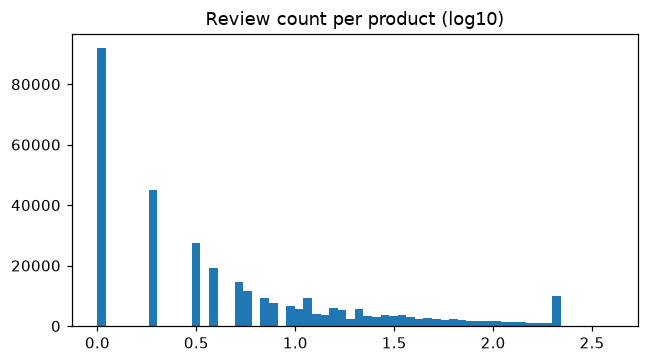

In [21]:
pp = per_prod.collect()["n_comments"]
qs = [.5, .75, .9, .95, .99, .999]
print(pl.DataFrame({"q": qs, "n_comments": [float(pp.quantile(q)) for q in qs]}))
print("max:", pp.max())

for th in [1, 5, 10, 20, 50, 100]:
    print(f"محصولات با >= {th:>3} نظر: {(pp >= th).sum():>8,}")

# سهم تجمعی: چند درصد نظرها در چند درصد محصولات متمرکز است؟
srt = np.sort(pp.to_numpy())[::-1]
cum = np.cumsum(srt) / srt.sum()
for frac in [0.01, 0.05, 0.1, 0.2]:
    print(f"{frac*100:.0f}% بالاترین محصولات = {cum[max(0, int(np.ceil(len(srt)*frac)) - 1)]*100:.1f}% از کل نظرها")

plt.figure(figsize=(6, 3.4))
plt.hist(np.log10(pp.to_numpy()), bins=60); plt.title("Review count per product (log10)")
plt.tight_layout(); plt.show()

### ۵. کیفیت متن فارسی
روی یک **نمونه‌ی ۵٪ی تصادفی** (انتخاب با hash روی `id`، پس کاملاً قابل بازتولید) کار می‌کنیم تا رم پر نشود.

In [22]:
# در داده، مقدار خالی گاهی به‌صورت رشته‌ی "nan" ذخیره شده؛ اینجا به "" تبدیل می‌شود
def clean_tok(c):
    v = pl.col(c).cast(pl.Utf8).str.strip_chars()
    return (pl.when(v.is_null() | v.str.to_lowercase().is_in(MISSING_TOKENS))
              .then(pl.lit("")).otherwise(v).alias(c))

cs = (comments.filter(pl.col(CC["id"]).hash(SEED) % 20 == 0)
      .with_columns([clean_tok(c) for c in text_cols])
      .with_columns(
          pl.concat_list([pl.col(c) for c in text_cols])
            .list.eval(pl.element().filter(pl.element() != ""))
            .list.join(" . ").alias("full_text"))
      .collect())
print("حجم نمونه:", cs.height)
STATS["text_sample_size"] = cs.height

حجم نمونه: 307746


In [23]:
patterns = {
    "arabic_yeh_ي":      r"\x{064A}",
    "arabic_kaf_ك":      r"\x{0643}",
    "arabic_digits_٠-٩": r"[\u0660-\u0669]",
    "persian_digits_۰-۹": r"[\u06F0-\u06F9]",
    "latin_digits":      r"[0-9]",
    "latin_letters":     r"[A-Za-z]",
    "tatweel_ـ":         r"\x{0640}",
    "zwnj_نیم‌فاصله":    r"\x{200C}",
    "url":               r"https?://|www\.",
    "html_tag":          r"<[^>]+>",
    "emoji_or_symbol":   r"[\u2190-\u2BFF\U0001F000-\U0001FAFF]",
    "multi_space":       r"\s{2,}",
    "newline":           r"[\n\r]",
}
rows = []
for name, pat in patterns.items():
    k = cs.select(pl.col("full_text").str.contains(pat).sum()).item()
    rows.append((name, k, round(k / max(cs.height, 1) * 100, 2)))
# elongation نیاز به backreference دارد (در regex پولارز پشتیبانی نمی‌شود) -> با re پایتون
_re_el = re.compile(r"([^\d\s])\1{2,}")
k = sum(1 for t in cs["full_text"].to_list() if _re_el.search(t))
rows.append(("elongation_3+", k, round(k / max(cs.height, 1) * 100, 2)))
issues = pl.DataFrame(rows, schema=["issue", "n_comments", "pct"], orient="row").sort("pct", descending=True)
STATS["text_issues_pct"] = dict(zip(issues["issue"], issues["pct"]))
issues

issue,n_comments,pct
str,i64,f64
"""multi_space""",27049,8.79
"""newline""",25700,8.35
"""elongation_3+""",14357,4.67
"""latin_letters""",13751,4.47
"""persian_digits_۰-۹""",10873,3.53
"""zwnj_نیم‌فاصله""",10553,3.43
"""latin_digits""",7318,2.38
"""arabic_yeh_ي""",2926,0.95
"""emoji_or_symbol""",2741,0.89


In [24]:
# این نمونه‌ها همان نرمال‌سازی استفاده‌شده در خط پردازش را نشان می‌دهند.
examples = ["كيفيت عاااالي بود !!!!", "قیمت ۱۲۰۰۰۰ تومان www.test.com", "<br>خوب بود &amp; ممنون"]
for example in examples:
    print(repr(example), "→", repr(normalize_persian_text(example)))


'كيفيت عاااالي بود !!!!' → 'کیفیت عاااالی بود !!!!'
'قیمت ۱۲۰۰۰۰ تومان www.test.com' → 'قیمت 120000 تومان'
'<br>خوب بود &amp; ممنون' → 'خوب بود & ممنون'


shape: (9, 3)
┌────────────┬───────────┬───────────┐
│ statistic  ┆ n_chars   ┆ n_words   │
│ ---        ┆ ---       ┆ ---       │
│ str        ┆ f64       ┆ f64       │
╞════════════╪═══════════╪═══════════╡
│ count      ┆ 307746.0  ┆ 307746.0  │
│ null_count ┆ 0.0       ┆ 0.0       │
│ mean       ┆ 61.999178 ┆ 13.063861 │
│ std        ┆ 75.150432 ┆ 15.434182 │
│ min        ┆ 0.0       ┆ 0.0       │
│ 25%        ┆ 21.0      ┆ 5.0       │
│ 50%        ┆ 39.0      ┆ 8.0       │
│ 75%        ┆ 76.0      ┆ 16.0      │
│ max        ┆ 2843.0    ┆ 614.0     │
└────────────┴───────────┴───────────┘
نظر با متن <= 0 کاراکتر: 1 (0.00%)
نظر با متن <= 3 کاراکتر: 2,839 (0.92%)
نظر با متن <= 5 کاراکتر: 13,256 (4.31%)
نظر با متن <= 10 کاراکتر: 28,014 (9.10%)
نظر با متن <= 20 کاراکتر: 75,502 (24.53%)


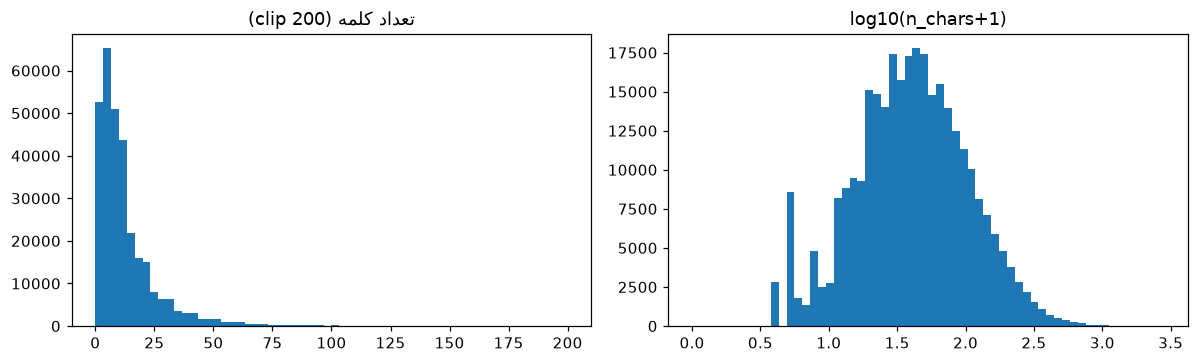

shape: (15, 2)
┌───────────────────┬──────┐
│ full_text         ┆ len  │
│ ---               ┆ ---  │
│ str               ┆ u32  │
╞═══════════════════╪══════╡
│ عالی              ┆ 4886 │
│ خوبه              ┆ 3233 │
│ خوب بود           ┆ 3178 │
│ خوب               ┆ 2732 │
│ عالی . عالی       ┆ 976  │
│ عالی بود          ┆ 919  │
│ عالیه             ┆ 780  │
│ معمولی            ┆ 570  │
│ خیلی خوب بود      ┆ 516  │
│ خوب . خوب         ┆ 486  │
│ خوب بود . خوب بود ┆ 426  │
│ خیلی خوبه         ┆ 384  │
│ بد نیست           ┆ 355  │
│ خوبه . خوبه       ┆ 351  │
│ بسیار عالی        ┆ 298  │
└───────────────────┴──────┘


In [25]:
# طول متن (کاراکتر/کلمه) و نظرهای خیلی کوتاه
cs = cs.with_columns([
    pl.col("full_text").str.len_chars().alias("n_chars"),
    pl.col("full_text").str.count_matches(r"\S+").alias("n_words"),
])
print(cs.select(["n_chars", "n_words"]).describe())
for th in [0, 3, 5, 10, 20]:
    k = cs.filter(pl.col("n_chars") <= th).height
    print(f"نظر با متن <= {th} کاراکتر: {k:,} ({k / max(cs.height, 1) * 100:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(np.clip(cs["n_words"].to_numpy(), 0, 200), bins=60); ax[0].set_title("تعداد کلمه (clip 200)")
ax[1].hist(np.log10(cs["n_chars"].to_numpy() + 1), bins=60);   ax[1].set_title("log10(n_chars+1)")
plt.tight_layout(); plt.show()

# پرتکرارترین متن‌های خیلی کوتاه
print(cs.filter(pl.col("n_chars") < 25).group_by("full_text").len()
        .sort("len", descending=True).head(15))

### ۶. برچسب `recommendation_status` (مربوط به بخش سوم)
بررسی: نامتوازنی کلاس‌ها، نویز برچسب (یک متن، چند برچسب)، رابطه با امتیاز و طول متن، و ساختار نشت احتمالی.

In [26]:
lab = cs.group_by(st).len().sort("len", descending=True)
lab = lab.with_columns((pl.col("len") / max(cs.height, 1) * 100).round(2).alias("pct"))
print(lab)
STATS["label_dist_sample"] = {row[st]: row["len"] for row in lab.to_dicts()}

# نسبت کلاس بزرگ به کوچک
valid_counts = lab.filter(pl.col(st).is_in(LABELS))["len"]
if len(valid_counts) > 0:
    imbalance_ratio = valid_counts.max() / valid_counts.min()
    STATS["valid_label_imbalance_ratio"] = imbalance_ratio
    print(f"imbalance ratio (valid labels only): {imbalance_ratio:.1f}")

# طول متن به تفکیک برچسب: آیا no_idea بیشتر متن‌خالی است؟
print(cs.group_by(st).agg(
    pl.col("n_words").mean().round(1).alias("mean_words"),
    pl.col("n_words").median().alias("median_words"),
    (pl.col("n_chars") <= 10).mean().round(3).alias("share_text_at_most_10_chars"),
    pl.col(r).mean().round(2).alias("mean_rate"),
))

shape: (4, 3)
┌───────────────────────┬────────┬───────┐
│ recommendation_status ┆ len    ┆ pct   │
│ ---                   ┆ ---    ┆ ---   │
│ str                   ┆ u32    ┆ f64   │
╞═══════════════════════╪════════╪═══════╡
│ recommended           ┆ 207775 ┆ 67.52 │
│ nan                   ┆ 44764  ┆ 14.55 │
│ no_idea               ┆ 29892  ┆ 9.71  │
│ not_recommended       ┆ 25315  ┆ 8.23  │
└───────────────────────┴────────┴───────┘
imbalance ratio (valid labels only): 8.2
shape: (4, 5)
┌───────────────────────┬────────────┬──────────────┬─────────────────────────────┬───────────┐
│ recommendation_status ┆ mean_words ┆ median_words ┆ share_text_at_most_10_chars ┆ mean_rate │
│ ---                   ┆ ---        ┆ ---          ┆ ---                         ┆ ---       │
│ str                   ┆ f64        ┆ f64          ┆ f64                         ┆ f64       │
╞═══════════════════════╪════════════╪══════════════╪═════════════════════════════╪═══════════╡
│ recommended        

In [27]:
# نویز برچسب: متن یکسان با برچسب‌های متفاوت
# «nan» برچسب نیست و نباید تعارض برچسب بسازد.
txt = cs.filter((pl.col("n_chars") > 25) & pl.col(st).is_in(LABELS))
g = txt.group_by("full_text").agg(pl.col(st).n_unique().alias("n_labels"), pl.len().alias("n"))
multi = g.filter((pl.col("n") > 1))
conflict = multi.filter(pl.col("n_labels") > 1)
print(f"متن‌های تکراری: {multi.height:,} | با برچسب متناقض: {conflict.height:,}")
print(conflict.sort("n", descending=True).head(5))

# سازگاری برچسب با امتیاز: recommended با امتیاز خیلی کم، یا not_recommended با امتیاز زیاد
print("\nrecommended با rate<=2:",
      cs.filter((pl.col(st) == "recommended") & (pl.col(r) <= 2)).height)
print("not_recommended با rate>=4:",
      cs.filter((pl.col(st) == "not_recommended") & (pl.col(r) >= 4)).height)
STATS["conflicting_valid_label_groups_on_sample"] = conflict.height

متن‌های تکراری: 1,104 | با برچسب متناقض: 73
shape: (5, 3)
┌─────────────────────────────────────────┬──────────┬─────┐
│ full_text                               ┆ n_labels ┆ n   │
│ ---                                     ┆ ---      ┆ --- │
│ str                                     ┆ u32      ┆ u32 │
╞═════════════════════════════════════════╪══════════╪═════╡
│ خیلی خوب بود . خیلی خوب بود             ┆ 3        ┆ 24  │
│ خوبه بد نیست . خوبه بد نیست             ┆ 2        ┆ 17  │
│ خوب بود . ممنون از دیجی کالا             ┆ 3        ┆ 15  │
│ نسبت به قیمتش خوبه . نسبت به قیمتش خوبه ┆ 2        ┆ 14  │
│ تو شگفت انگیز ارزش خرید داره            ┆ 2        ┆ 12  │
└─────────────────────────────────────────┴──────────┴─────┘

recommended با rate<=2: 22756
not_recommended با rate>=4: 648


In [28]:
# ساختار نشت: برچسب‌ها در سطح محصول چقدر متمرکز است؟
# اگر نظرهای یک محصول هم در train هم در test باشند، مدل می‌تواند «نام/ویژگی محصول» را حفظ کند.
pl_lab = (comments.filter(pl.col(st).is_in(["recommended", "not_recommended", "no_idea"]))
          .group_by([pid_c, st]).len().collect()
          .pivot(on=st, index=pid_c, values="len").fill_null(0))
print(pl_lab.head())
tot = pl_lab.select(pl.sum_horizontal(pl.exclude(pid_c)).alias("n"))["n"]
STATS["products_with_at_least_20_labeled_reviews"] = int((tot >= 20).sum())
print("محصولات با >=20 نظر برچسب‌دار:", STATS["products_with_at_least_20_labeled_reviews"])
if "not_recommended" in pl_lab.columns:
    share = (pl_lab["not_recommended"] / tot).filter(tot >= 20)
    print("پراکندگی سهم not_recommended بین محصولات (>=20 نظر):")
    print(share.describe())
print("\n=> نتیجه: تقسیم train/val/test باید GroupSplit بر اساس product_id باشد، و تکراری‌ها قبل از تقسیم حذف شوند.")

shape: (5, 4)
┌────────────┬─────────────┬─────────────────┬─────────┐
│ product_id ┆ recommended ┆ not_recommended ┆ no_idea │
│ ---        ┆ ---         ┆ ---             ┆ ---     │
│ str        ┆ u32         ┆ u32             ┆ u32     │
╞════════════╪═════════════╪═════════════════╪═════════╡
│ 2596259    ┆ 26          ┆ 3               ┆ 8       │
│ 8207159    ┆ 0           ┆ 1               ┆ 0       │
│ 4122162    ┆ 131         ┆ 12              ┆ 21      │
│ 9456132    ┆ 3           ┆ 0               ┆ 0       │
│ 7107851    ┆ 3           ┆ 3               ┆ 0       │
└────────────┴─────────────┴─────────────────┴─────────┘
محصولات با >=20 نظر برچسب‌دار: 55022
پراکندگی سهم not_recommended بین محصولات (>=20 نظر):
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 55022.0  │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.094833 │
│ std        ┆ 0.087863 │
│ min        ┆ 0.0   

### تصمیم‌های اجرایی بر اساس EDA

| یافته | پیاده‌سازی در بخش B |
|---|---|
| شناسهٔ تکراری محصول یا نظر | یک ردیف نماینده با ترتیب ثابت انتخاب می‌شود. برای قیمت‌های متفاوتِ یک محصول پرچم اختلاف ذخیره می‌شود. |
| قیمت نامعتبر و قیمت‌های بزرگ | قیمت نامعتبر خالی می‌شود؛ قیمت مثبتِ پرت برای تحلیل باقی می‌ماند. تبدیل به تومان پس از تأیید واحد فعال می‌شود. |
| امتیاز محصول صفر، شمار آرا و امتیاز نظر | امتیاز محصول فقط با رأی مثبت و در بازهٔ معتبر استفاده می‌شود. امتیاز نظر خارج از ۰ تا ۵ خالی می‌شود. |
| نبود اتصال نظر به محصول، متن یا برچسب | نظر بدون محصول کنار گذاشته می‌شود. نظرِ دارای محصول و فاقد متن یا برچسب در آمار کل باقی می‌ماند؛ ورود به RAG و طبقه‌بندی شرایط جدا دارد. |
| تفاوت رسم‌الخط و فهرست‌های متنی | ستون‌های نسخهٔ خام برای ارجاع حفظ و نسخه‌های تمیز برای مدل و بازیابی ساخته می‌شوند. |
| تکرار متن، تعارض و نامتوازنی برچسب | گروه‌بندی با شناسهٔ محصول و حذف تکرار دو نمای متن. سقف کلاس‌ها فقط در بخش آموزش اعمال می‌شود. |
| تمرکز نظرات روی برخی محصولات | آمار روی مجموعهٔ کامل و نمونهٔ RAG با سقف نظر برای هر محصول ساخته می‌شوند. |
| قیمت ماه گذشته و نشانگر غیراصل | قیمت ماه گذشته در کاتالوگ خروجی استفاده نمی‌شود. نشانگر غیراصل به شکل فیلد جدا باقی می‌ماند. |

شمارش‌های این بخش، ممیزی دادهٔ خام هستند. تعداد حذف‌های بخش B بر اساس ترتیب واقعی مراحل پاک‌سازی در `preprocessing_report.json` ثبت می‌شود.

In [29]:
eda_report = output_root / "eda_summary.json"
eda_staged = staging / eda_report.name
eda_staged.write_text(json.dumps(STATS, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
os.replace(eda_staged, eda_report)
print("گزارش EDA:", eda_report)
print("محصولات و نظرات خام:", N_PRODUCTS_RAW, N_COMMENTS_RAW)
print("تکرار شناسهٔ محصول و نظر:", STATS["products_dup_ids"], STATS["comments_dup_ids"])
print("محصولات دارای نظر و نظرات بدون محصول:", STATS["products_with_comments"], STATS["orphan_comments"])

گزارش EDA: C:\Users\fateme shakiba\Desktop\pro3\data\processed_repo_based\eda_summary.json
محصولات و نظرات خام: 1283496 6156289
تکرار شناسهٔ محصول و نظر: 335144 3229
محصولات دارای نظر و نظرات بدون محصول: 331599 0


## بخش B · پیش‌پردازش و ساخت دادهٔ پروژه

پاک‌سازی از همان داده‌ای شروع می‌شود که در بخش A بررسی شد. سلول‌های زیر فایل‌های Parquet، نمونهٔ بازیابی و گزارش کنترل خروجی را می‌سازند.

### ۲. پاک‌سازی محصولات

هر محصول یک ردیف دارد. برای شناسهٔ تکراری، اول ردیف دارای عنوان و قیمت معتبر و سپس ردیفی با دسته و اطلاعات کامل‌تر و تعداد امتیاز بیشتر ترجیح داده می‌شود. چون داده زمان ثبت ردیف محصول ندارد، در صورت تفاوت قیمت، کمینه و بیشینهٔ مشاهده‌شده و پرچم `price_conflict` ذخیره می‌شوند. قیمت نمایندهٔ یک ردیف موجود در داده است.

قیمت صفر و نامعتبر به مقدار خالی تبدیل می‌شود. قیمت‌های مثبتِ بزرگ برای تحلیل حفظ می‌شوند. واحد قیمت در دادهٔ ورودی تصریح نشده است. تا زمان تأیید، از فیلد `price` فقط به‌عنوان مقدار ثبت‌شده در داده استفاده می‌کنیم و `price_toman` خالی می‌ماند. `rating_100` فقط برای امتیاز معتبر با تعداد رأی مثبت پر می‌شود.

طبق EDA، `min_price_last_month` در بیشتر ردیف‌ها مقدار صفر داشت. این ستون در کاتالوگ تمیز استفاده نمی‌شود.

`product_text_norm` متن آمادهٔ نمایهٔ معناییِ کالا از عنوان، دسته‌ها و برند است. `product_text_lexical` برای جست‌وجوی واژگانی آماده است. عنوان خام و فیلدهای مستقل برای نمایش و فیلتر باقی می‌مانند.

In [30]:
price_toman = {None: "NULL::DOUBLE", "rial": "price / 10.0", "toman": "price"}[PRICE_UNIT]
con.execute(f'''
    CREATE OR REPLACE TABLE products AS
    WITH typed AS (
        SELECT missing(id) AS product_id, title_fa AS title_raw,
               normalize_fa(title_fa) AS title_fa,
               normalize_fa(Category1) AS category1, normalize_fa(Category2) AS category2,
               normalize_fa(sub_category) AS sub_category, normalize_fa(Brand) AS brand,
               normalize_fa(Seller) AS seller, clean_bool(Is_Fake) AS is_fake,
               missing(Price) AS price_raw, clean_number(Price) AS raw_price_number,
               whole_nonnegative(clean_number(Rate_cnt)) AS rating_count,
               clean_number(Rate) AS raw_rating
          FROM raw_products
         WHERE missing(id) IS NOT NULL
    ), ready AS (
        SELECT * EXCLUDE (raw_price_number, raw_rating),
               CASE WHEN isfinite(raw_price_number) AND raw_price_number > 0
                    THEN raw_price_number END AS price,
               CASE WHEN raw_rating > 0 AND raw_rating <= 100 AND rating_count > 0
                    THEN raw_rating END AS rating_100,
               coalesce((rating_count > 0 AND raw_rating = 0)
                        OR (rating_count = 0 AND raw_rating > 0), false)
                    AS rating_count_conflict
          FROM typed
    ), ranked AS (
        SELECT *, count(*) OVER product AS source_rows,
               min(price) OVER product AS observed_min_price,
               max(price) OVER product AS observed_max_price,
               row_number() OVER (
                   PARTITION BY product_id
                   ORDER BY (title_fa IS NOT NULL) DESC, (price IS NOT NULL) DESC,
                            (category1 IS NOT NULL) DESC,
                            ((category2 IS NOT NULL)::INT + (brand IS NOT NULL)::INT
                              + (seller IS NOT NULL)::INT + (is_fake IS NOT NULL)::INT
                              + (sub_category IS NOT NULL)::INT) DESC,
                            rating_count DESC NULLS LAST, rating_100 DESC NULLS LAST,
                            price ASC NULLS LAST, price_raw, title_fa, title_raw,
                            category1, category2, sub_category, brand, seller, is_fake,
                            rating_count_conflict
               ) AS choice
          FROM ready WINDOW product AS (PARTITION BY product_id)
    )
    SELECT * EXCLUDE (choice), price IS NOT NULL AS price_valid,
           coalesce(observed_max_price <> observed_min_price, false) AS price_conflict,
           {price_toman} AS price_toman,
           nullif(concat_ws(' ', title_fa, category1, category2, sub_category, brand), '')
               AS product_text_norm,
           lexical_text(concat_ws(' ', title_fa, category1, category2, sub_category, brand))
               AS product_text_lexical
      FROM ranked WHERE choice = 1
''')
report["products"] = records('''
    SELECT count(*) AS rows,
           coalesce(sum(source_rows - 1), 0) AS duplicate_id_rows_removed,
           count(*) FILTER (WHERE NOT price_valid) AS invalid_or_missing_price,
           count(*) FILTER (WHERE price_conflict) AS product_ids_with_price_conflict,
           count(*) FILTER (WHERE rating_100 IS NULL) AS missing_or_invalid_rating,
           count(*) FILTER (WHERE rating_count_conflict) AS rating_count_conflicts
      FROM products
''')[0]
report["products"]["missing_id_rows"] = count("raw_products", "missing(id) IS NULL")
print("محصولات:", report["products"])

محصولات: {'rows': 948352, 'duplicate_id_rows_removed': 335144, 'invalid_or_missing_price': 156, 'product_ids_with_price_conflict': 8212, 'missing_or_invalid_rating': 587378, 'rating_count_conflicts': 15, 'missing_id_rows': 0}


### ۳. پاک‌سازی نظرات

شناسهٔ نظر برای ارجاع به متن اصلی حفظ می‌شود. ابتدا شناسه‌های تکراری حذف می‌شوند. سپس اگر محصول، تاریخ و هر چهار فیلد متن یکسان باشند، یک ردیف نگه داشته می‌شود. در این دو مرحله، اگر برچسب‌های معتبر یک گروه با هم اختلاف داشته باشند، برچسب نماینده خالی و `label_conflict` فعال می‌شود. نظرات بدون محصول مرتبط کنار گذاشته و شمارش می‌شوند.

برای تحلیل، نظرهای بدون متن یا بدون برچسب همچنان در جدول پاک‌شده می‌مانند. ستون `text_clean` فقط عنوان، متن، مزایا و معایب را ترکیب می‌کند و فیلدهای کاملاً یکسان را یک بار می‌آورد. امتیاز، رأی‌ها، فروشنده، تاریخ و وضعیت خریدار در ورودی مدل قرار نمی‌گیرند. امتیاز نظر خارج از بازهٔ ۰ تا ۵ خالی می‌شود و صفر ثبت‌شده حفظ می‌شود.

از مزایا و معایبِ لیست‌مانند، آیتم‌ها جدا و با «؛» به هم وصل می‌شوند. مقدار خراب به شکل متن نگه داشته می‌شود. تاریخ فقط برای مقادیر متمایز به میلادی تبدیل می‌شود و در `created_at_gregorian` می‌آید. تاریخ شمسی خام برای ردیابی باقی می‌ماند.

In [31]:
print("پاک‌سازی متن و آماده‌سازی نظرها شروع شد…")
con.execute(r'''
    CREATE OR REPLACE TABLE normalized_comments AS
    SELECT missing(c.id) AS comment_id, p.product_id,
           c.title AS title_raw, c.body AS body_raw,
           c.advantages AS advantages_raw, c.disadvantages AS disadvantages_raw,
           normalize_fa(c.title) AS title_clean, normalize_fa(c.body) AS body_clean,
           aspect_text(missing(c.advantages)) AS advantages_clean,
           aspect_text(missing(c.disadvantages)) AS disadvantages_clean,
           missing(c.created_at) AS created_at_raw,
           try_cast(regexp_extract(unify_chars(missing(c.created_at)), '([0-9]{4})$', 1)
                    AS SMALLINT) AS year_jalali,
           missing(c.rate) AS rating_raw,
           CASE WHEN clean_number(c.rate) BETWEEN 0 AND 5 THEN clean_number(c.rate) END
                AS rating_5,
           missing(c.recommendation_status) AS recommendation_status_raw,
           clean_label(c.recommendation_status) AS source_label,
           clean_bool(c.is_buyer) AS is_buyer,
           whole_nonnegative(clean_number(c.likes)) AS likes,
           whole_nonnegative(clean_number(c.dislikes)) AS dislikes,
           normalize_fa(c.seller_title) AS seller_title,
           missing(c.seller_code) AS seller_code,
           missing(c.true_to_size_rate) AS true_to_size_rate,
           md5(CAST(to_json(struct_pack(
               title := missing(c.title), body := missing(c.body),
               adv := missing(c.advantages), dis := missing(c.disadvantages))) AS VARCHAR))
                AS raw_text_key
      FROM raw_comments c
      JOIN products p ON missing(c.product_id) = p.product_id
     WHERE missing(c.id) IS NOT NULL
''')
input_comments = report["inputs"]["comments"]["rows"]
report["comments"] = {
    "missing_comment_ids": count("raw_comments", "missing(id) IS NULL"),
    "rows_with_product_and_comment_id": count("normalized_comments"),
}
report["comments"]["orphan_rows_with_comment_id"] = (
    input_comments - report["comments"]["missing_comment_ids"]
    - report["comments"]["rows_with_product_and_comment_id"]
)
print("متن نظرها نرمال شد:", report["comments"])

پاک‌سازی متن و آماده‌سازی نظرها شروع شد…
متن نظرها نرمال شد: {'missing_comment_ids': 0, 'rows_with_product_and_comment_id': 6156289, 'orphan_rows_with_comment_id': 0}


In [32]:
con.execute(r'''
    CREATE OR REPLACE TABLE unique_comments AS
    WITH id_ranked AS (
        SELECT *, min(source_label) OVER same_id AS id_label_min,
               max(source_label) OVER same_id AS id_label_max,
               row_number() OVER (PARTITION BY comment_id ORDER BY
                   list_unique([title_clean, body_clean, advantages_clean, disadvantages_clean]) DESC,
                   (source_label IS NOT NULL) DESC, (created_at_raw IS NOT NULL) DESC,
                   (rating_5 IS NOT NULL) DESC,
                   md5(CAST(to_json(struct_pack(
                       pid := product_id, title := title_raw, body := body_raw,
                       adv := advantages_raw, dis := disadvantages_raw,
                       date := created_at_raw, status := recommendation_status_raw,
                       rate := rating_raw, b := is_buyer, l := likes, d := dislikes,
                       seller := seller_title, code := seller_code, size := true_to_size_rate))
                       AS VARCHAR))
               ) AS choice
          FROM normalized_comments WINDOW same_id AS (PARTITION BY comment_id)
    )
    SELECT * EXCLUDE (choice, id_label_min, id_label_max, source_label),
           coalesce(id_label_min <> id_label_max, false) AS id_label_conflict,
           CASE WHEN id_label_min = id_label_max THEN id_label_min END AS source_label,
           CASE WHEN created_at_raw IS NOT NULL
                      AND coalesce(body_clean, title_clean, advantages_clean, disadvantages_clean)
                          IS NOT NULL
                THEN md5(CAST(to_json(struct_pack(
                    pid := product_id, date := normalize_fa(created_at_raw), txt := raw_text_key))
                    AS VARCHAR))
                ELSE concat('id:', comment_id) END AS content_key
      FROM id_ranked WHERE choice = 1
''')
report["comments"]["duplicate_comment_id_rows_removed"] = (
    report["comments"]["rows_with_product_and_comment_id"] - count("unique_comments")
)
con.execute("DROP TABLE normalized_comments")

con.execute(r'''
    CREATE OR REPLACE TABLE comments AS
    WITH content_ranked AS (
        SELECT *, min(source_label) OVER same_content AS label_min,
               max(source_label) OVER same_content AS label_max,
               bool_or(id_label_conflict) OVER same_content AS any_id_conflict,
               row_number() OVER (PARTITION BY content_key ORDER BY
                   (source_label IS NOT NULL) DESC, (rating_5 IS NOT NULL) DESC, comment_id
               ) AS choice
          FROM unique_comments WINDOW same_content AS (PARTITION BY content_key)
    ), combined AS (
        SELECT * EXCLUDE (choice, source_label, label_min, label_max, raw_text_key,
                          content_key, id_label_conflict, any_id_conflict),
               any_id_conflict OR coalesce(label_min <> label_max, false) AS label_conflict,
               CASE WHEN NOT any_id_conflict AND label_min = label_max
                    THEN label_min END AS recommendation_status,
               nullif(concat_ws(' . ',
                   title_clean,
                   CASE WHEN body_clean IS DISTINCT FROM title_clean THEN body_clean END,
                   CASE WHEN advantages_clean IS DISTINCT FROM title_clean
                         AND advantages_clean IS DISTINCT FROM body_clean THEN advantages_clean END,
                   CASE WHEN disadvantages_clean IS DISTINCT FROM title_clean
                         AND disadvantages_clean IS DISTINCT FROM body_clean
                         AND disadvantages_clean IS DISTINCT FROM advantages_clean
                        THEN disadvantages_clean END), '') AS text_clean
          FROM content_ranked WHERE choice = 1
    ), dates AS MATERIALIZED (
        SELECT created_at_raw, jalali_to_date(created_at_raw) AS created_at_gregorian
          FROM (SELECT DISTINCT created_at_raw FROM unique_comments WHERE created_at_raw IS NOT NULL)
    ), signals AS (
        SELECT combined.*, dates.created_at_gregorian, review_chars(text_clean) AS comparable_text,
               len(regexp_extract_all(text_clean, '[\p{L}\p{N}][\p{L}\p{N}\x{200C}]*'))
                  AS word_count
          FROM combined LEFT JOIN dates USING (created_at_raw)
    )
    SELECT * EXCLUDE (comparable_text),
           md5(nullif(comparable_text, '')) AS text_key,
           coalesce((word_count >= 2 AND length(comparable_text) >= 8)
                    OR regexp_matches(coalesce(advantages_clean, '') || ' ' ||
                                      coalesce(disadvantages_clean, ''), '\p{L}'), false)
                AS rag_eligible
      FROM signals
''')
report["comments"]["duplicate_content_rows_removed"] = count("unique_comments") - count("comments")
con.execute("DROP TABLE unique_comments")
report["comments"].update(records('''
    SELECT count(*) AS rows,
           count(*) FILTER (WHERE text_clean IS NULL) AS no_text,
           count(*) FILTER (WHERE text_key IS NULL) AS no_classification_text,
           count(*) FILTER (WHERE recommendation_status IS NULL) AS missing_or_unusable_label,
           count(*) FILTER (WHERE label_conflict) AS label_conflicts,
           count(*) FILTER (WHERE rating_raw IS NOT NULL AND rating_5 IS NULL) AS invalid_rating,
           count(*) FILTER (WHERE rag_eligible) AS rag_eligible,
           count(*) FILTER (WHERE created_at_gregorian IS NOT NULL) AS parsed_gregorian_date,
           count(*) FILTER (WHERE created_at_raw IS NOT NULL AND created_at_gregorian IS NULL)
               AS unparsed_nonmissing_dates
      FROM comments
''')[0])
report["comments"]["label_distribution"] = records('''
    SELECT recommendation_status, count(*) AS n FROM comments
    GROUP BY recommendation_status ORDER BY n DESC, recommendation_status
''')
print("نظرات:", report["comments"])

نظرات: {'missing_comment_ids': 0, 'rows_with_product_and_comment_id': 6156289, 'orphan_rows_with_comment_id': 0, 'duplicate_comment_id_rows_removed': 3229, 'duplicate_content_rows_removed': 1757, 'rows': 6151303, 'no_text': 17, 'no_classification_text': 192, 'missing_or_unusable_label': 893686, 'label_conflicts': 120, 'invalid_rating': 1, 'rag_eligible': 5617767, 'parsed_gregorian_date': 6151303, 'unparsed_nonmissing_dates': 0, 'label_distribution': [{'recommendation_status': 'recommended', 'n': 4159517}, {'recommendation_status': None, 'n': 893686}, {'recommendation_status': 'no_idea', 'n': 593619}, {'recommendation_status': 'not_recommended', 'n': 504481}]}


### ۴. دادهٔ جست‌وجو، بازیابی و تحلیل

آمار محصول از **همهٔ نظرات پاک‌شده** محاسبه می‌شود. `recommended_share_labeled` سهم پیشنهاد خرید از سه کلاس معتبر است. `recommended_share_decided` فقط نظرهایی را حساب می‌کند که خرید را پیشنهاد کرده‌اند یا نکرده‌اند. سهم‌ها عددی بین صفر و یک هستند و وقتی مخرج صفر باشد مقدار خالی می‌ماند. `category_coverage` به انتخاب دسته‌ای با پوشش محصول و نظر کافی کمک می‌کند.

فهرست RAG به‌طور پیش‌فرض حداکثر ۴۸ نظر برای هر محصول دارد. ابتدا نظر قابل استفاده انتخاب می‌شود و سپس وضعیت‌های پیشنهاد خرید به‌نوبت نمونه‌برداری می‌شوند تا دیدگاه‌های کم‌تعداد هم شانس دیده‌شدن داشته باشند. برای ساخت نمایه، `rag_review_index.parquet` را با `comments_clean.parquet` روی `comment_id` وصل کن. درصدها و ادعاهای پرتکرار باید با مجموعهٔ کامل یا نمونه‌گیری گزارش‌شده محاسبه شوند.

`rag_starter.parquet` یک پیکرهٔ اولیهٔ حداکثر ۱۵٬۰۰۰ نظری برای آزمایش بازیابی است. محصولات دارای دست‌کم ۱۰ متن متفاوت به‌صورت گردشی بین دسته‌های کلی انتخاب می‌شوند و هر محصول حداکثر ۲۴ نظر می‌دهد. این روش برای هر محصولِ منتخب چند شاهد فراهم می‌کند و هزینهٔ شروع نمایه‌سازی را محدود می‌کند. برای یک محصول بیرون از این نمونه از فهرست بزرگ‌تر و فیلتر شناسهٔ محصول استفاده کن. برای واژگان `text_lexical` و برای Dense، `text_clean` در دسترس‌اند.

In [33]:
con.execute('''
    CREATE OR REPLACE TABLE review_stats AS
    SELECT product_id, count(*) AS review_count,
           count(*) FILTER (WHERE is_buyer IS TRUE) AS buyer_review_count,
           count(*) FILTER (WHERE text_clean IS NOT NULL) AS text_review_count,
           count(*) FILTER (WHERE rag_eligible) AS rag_eligible_count,
           count(*) FILTER (WHERE recommendation_status = 'recommended') AS recommended_count,
           count(*) FILTER (WHERE recommendation_status = 'not_recommended') AS not_recommended_count,
           count(*) FILTER (WHERE recommendation_status = 'no_idea') AS no_idea_count,
           count(recommendation_status) AS labeled_count,
           count(rating_5) AS rated_review_count,
           avg(rating_5) AS mean_review_rating_5,
           recommended_count::DOUBLE / nullif(labeled_count, 0) AS recommended_share_labeled,
           recommended_count::DOUBLE / nullif(recommended_count + not_recommended_count, 0)
               AS recommended_share_decided
      FROM comments GROUP BY product_id
''')
con.execute('''
    CREATE OR REPLACE TABLE category_coverage AS
    WITH totals AS (
        SELECT p.sub_category, p.category1, p.category2, count(*) AS product_count,
               count(s.product_id) AS products_with_reviews,
               count(*) FILTER (WHERE p.price_valid) AS products_with_valid_price,
               coalesce(sum(s.review_count), 0) AS review_count,
               coalesce(sum(s.rag_eligible_count), 0) AS rag_eligible_count,
               coalesce(sum(s.labeled_count), 0) AS labeled_count,
               coalesce(sum(s.recommended_count), 0) AS recommended_count,
               coalesce(sum(s.not_recommended_count), 0) AS not_recommended_count,
               coalesce(sum(s.no_idea_count), 0) AS no_idea_count
          FROM products p LEFT JOIN review_stats s USING (product_id)
         GROUP BY p.sub_category, p.category1, p.category2
    )
    SELECT *, recommended_count::DOUBLE / nullif(labeled_count, 0) AS recommended_share_labeled
      FROM totals
''')

rag_filter = "" if RAG_MAX_PER_PRODUCT is None else f"WHERE review_rank <= {RAG_MAX_PER_PRODUCT}"
con.execute(f'''
    CREATE OR REPLACE TABLE rag_review_index AS
    WITH status_rank AS (
        SELECT comment_id, product_id, recommendation_status,
               md5_number_lower(concat('{SEED}:rag:', comment_id)) AS review_order,
               row_number() OVER (
                   PARTITION BY product_id, recommendation_status
                   ORDER BY review_order, comment_id
               ) AS status_rank
          FROM comments WHERE rag_eligible
    ), product_rank AS (
        SELECT product_id, comment_id, row_number() OVER (
                   PARTITION BY product_id ORDER BY status_rank, review_order, comment_id
               ) AS review_rank
          FROM status_rank
    )
    SELECT * FROM product_rank {rag_filter}
''')
report["retrieval"] = {
    "rows_in_rag_index": count("rag_review_index"),
    "products_with_reviews": count("review_stats"),
    "products_in_rag_index": con.sql("SELECT count(DISTINCT product_id) FROM rag_review_index").fetchone()[0],
}
print("بازیابی:", report["retrieval"])
print("چند دسته با بیشترین نظر پاک‌شده:")
for row in records('''
    SELECT sub_category, category1, category2, product_count, review_count
    FROM category_coverage ORDER BY review_count DESC LIMIT 8
'''):
    print(row)

con.execute('''
    CREATE OR REPLACE TABLE brand_coverage AS
    WITH totals AS (
        SELECT p.sub_category, p.category1, p.brand,
               count(*) AS product_count, count(s.product_id) AS products_with_reviews,
               coalesce(sum(s.review_count), 0) AS review_count,
               coalesce(sum(s.labeled_count), 0) AS labeled_count,
               coalesce(sum(s.recommended_count), 0) AS recommended_count,
               coalesce(sum(s.not_recommended_count), 0) AS not_recommended_count,
               coalesce(sum(s.no_idea_count), 0) AS no_idea_count
          FROM products p LEFT JOIN review_stats s USING (product_id)
         GROUP BY p.sub_category, p.category1, p.brand
    )
    SELECT *, recommended_count::DOUBLE / nullif(labeled_count, 0) AS recommended_share_labeled
      FROM totals
''')

con.execute(f'''
    CREATE OR REPLACE TABLE rag_starter_ids AS
    WITH distinct_reviews AS (
        SELECT r.product_id, r.comment_id, r.review_rank
          FROM rag_review_index r JOIN comments c USING (comment_id)
        QUALIFY row_number() OVER (
            PARTITION BY r.product_id, coalesce(c.text_key, r.comment_id)
            ORDER BY r.review_rank, r.comment_id
        ) = 1
    ), candidate_products AS (
        SELECT r.product_id, p.sub_category,
               least(count(*), {RAG_STARTER_REVIEWS_PER_PRODUCT}) AS quota,
               md5_number_lower(concat('{SEED}:starter:', r.product_id)) AS product_hash
          FROM distinct_reviews r JOIN products p USING (product_id)
         GROUP BY r.product_id, p.sub_category HAVING count(*) >= {RAG_STARTER_MIN_REVIEWS}
    ), category_order AS (
        SELECT *, row_number() OVER (
                   PARTITION BY sub_category ORDER BY product_hash, product_id
               ) AS category_rank
          FROM candidate_products
    ), allocated AS (
        SELECT *, sum(quota) OVER (
                   ORDER BY category_rank, product_hash, product_id
                   ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
               ) - quota AS review_offset
          FROM category_order
    ), ranked AS (
        SELECT d.comment_id, d.product_id, a.sub_category, a.review_offset, a.quota,
               row_number() OVER (PARTITION BY d.product_id ORDER BY d.review_rank, d.comment_id)
                   AS local_review_rank
          FROM distinct_reviews d JOIN allocated a USING (product_id)
         WHERE a.review_offset < {RAG_STARTER_SIZE}
    )
    SELECT comment_id, product_id, sub_category,
           (review_offset + local_review_rank)::BIGINT AS corpus_rank
      FROM ranked WHERE local_review_rank <= quota
        AND review_offset + local_review_rank <= {RAG_STARTER_SIZE}
''')
report["retrieval"]["starter_rows"] = count("rag_starter_ids")
report["retrieval"]["starter_categories"] = records('''
    SELECT sub_category, count(DISTINCT product_id) AS products, count(*) AS reviews
      FROM rag_starter_ids GROUP BY sub_category ORDER BY sub_category
''')
print("پوشش نمونهٔ اولیهٔ RAG:", report["retrieval"]["starter_categories"])

بازیابی: {'rows_in_rag_index': 3445972, 'products_with_reviews': 331599, 'products_in_rag_index': 324092}
چند دسته با بیشترین نظر پاک‌شده:
{'sub_category': 'toys and kids', 'category1': 'اسباب بازی', 'category2': 'فکری و آموزشی', 'product_count': 20612, 'review_count': 215202}
{'sub_category': 'book & stationary & art', 'category1': 'کتاب شعر و ادبیات', 'category2': None, 'product_count': 20343, 'review_count': 172156}
{'sub_category': 'book & stationary & art', 'category1': 'کتاب کودک و نوجوان', 'category2': None, 'product_count': 14495, 'review_count': 134497}
{'sub_category': 'book & stationary & art', 'category1': 'کتاب فلسفه و روانشناسی', 'category2': None, 'product_count': 8921, 'review_count': 127005}
{'sub_category': 'beauty', 'category1': 'مراقبت پوست', 'category2': 'کرم مرطوب کننده و نرم کننده', 'product_count': 3386, 'review_count': 114892}
{'sub_category': 'beauty', 'category1': 'شامپو و مراقبت مو', 'category2': 'شامپو مو', 'product_count': 3667, 'review_count': 113847}
{'s

### ۵. تقسیم داده برای پیش‌بینی پیشنهاد خرید

- فقط ردیف دارای متن قابل استفاده و یکی از سه برچسب صریح وارد این مرحله می‌شود. `no_idea` یک کلاس معتبر است.
- هش متن نرمال‌شده تفاوت فاصله، نیم‌فاصله، بزرگی حروف و بیشتر نشانه‌گذاری‌ها را کنار می‌گذارد. از هر متن یک نماینده بر اساس هش شناسهٔ نظر و بدون توجه به برچسب انتخاب می‌شود.
- هش شناسهٔ محصول، آن را به‌صورت بازتولیدپذیر به یکی از سه بخش می‌فرستد. پیش‌فرض ۸۰/۱۰/۱۰ برای **محصول‌ها** است. به دلیل تفاوت تعداد نظرها، نسبت ردیف‌ها می‌تواند کمی متفاوت باشد.
- متن‌هایی که چند برچسب داشته‌اند از آموزش کنار گذاشته می‌شوند. اگر نمایندهٔ یک متن متناقض در اعتبارسنجی یا آزمون باشد، برچسب واقعی همان نظر حفظ می‌شود. شمار این موارد در گزارش هست.
- سقف نمونه‌گیری کلاس‌ها فقط روی آموزش اعمال می‌شود. اعتبارسنجی و آزمون در صورت نیاز با هش شناسه به‌صورت یکسان برای همهٔ کلاس‌ها کوچک می‌شوند. ترکیب کلاس‌های قبل و بعد از نمونه‌گیری در گزارش ثبت می‌شود.

این بررسی، متن یکسان با قواعد بالا را کنترل می‌کند. بازنویسی‌های معنایی و نظرهای بسیار شبیه با کلمات متفاوت می‌توانند باقی بمانند.

برای مقایسهٔ منصفانه، هر دو ورودی روی همان ردیف‌ها و تقسیم‌ها ذخیره می‌شوند. آزمایش اول `text_title_body` و آزمایش دوم `text_clean` با مزایا و معایب است. حذف تکرار و بررسی تعارض روی عنوان+متن و روی متن کامل انجام می‌شود. اگر یکی از دو نمای ورودی متن قابل استفاده نداشته باشد، آن نظر از دادهٔ مشترک آزمایش کنار می‌رود.

In [34]:
labels_sql = ", ".join(map(sql_string, LABELS))
con.execute(f'''
    CREATE OR REPLACE TABLE model_candidates AS
    SELECT comment_id, product_id, text_key, recommendation_status,
           review_hash(review_core(title_clean, body_clean)) AS core_text_key
      FROM comments
     WHERE text_key IS NOT NULL AND recommendation_status IN ({labels_sql})
       AND core_text_key IS NOT NULL
''')
report["classification"] = {
    "candidate_labels_before_text_dedup": records('''
        SELECT recommendation_status, count(*) AS n FROM model_candidates
        GROUP BY recommendation_status ORDER BY recommendation_status
    '''),
    "feature_columns": ["text_title_body", "text_clean"],
    "text_baseline": "text_title_body",
    "text_ablation": "text_clean",
    "both_feature_variants_required": True,
    "target": "recommendation_status",
}
con.execute(f'''
    CREATE OR REPLACE TABLE model_base AS

WITH ordered AS MATERIALIZED (
    SELECT *, struct_pack(
                h := md5_number_lower(concat('{SEED}:rep:', comment_id)), id := comment_id
              ) AS choice
      FROM model_candidates
), core_groups AS (
    SELECT core_text_key, arg_min(comment_id, choice) AS comment_id,
           min(recommendation_status) <> max(recommendation_status) AS core_conflict
      FROM ordered GROUP BY core_text_key
), full_conflicts AS (
    SELECT text_key FROM ordered GROUP BY text_key
    HAVING min(recommendation_status) <> max(recommendation_status)
), selected AS (
    SELECT c.* EXCLUDE (choice),
           g.core_conflict OR f.text_key IS NOT NULL AS text_label_conflict,
           md5_number_lower(concat('{SEED}:product:', c.product_id)) % 10000 AS split_bucket
      FROM ordered c JOIN core_groups g USING (core_text_key, comment_id)
      LEFT JOIN full_conflicts f USING (text_key)
    QUALIFY row_number() OVER (PARTITION BY c.text_key ORDER BY c.choice) = 1
)
    SELECT * EXCLUDE (split_bucket),
           CASE WHEN split_bucket < {TRAIN_PCT * 100} THEN 'train'
                WHEN split_bucket < {(TRAIN_PCT + VALIDATION_PCT) * 100} THEN 'validation'
                ELSE 'test' END AS split
      FROM selected
''')
con.execute("DROP TABLE model_candidates")
report["classification"]["before_sampling"] = records('''
    SELECT split, recommendation_status, count(*) AS n,
           count(*) FILTER (WHERE text_label_conflict) AS conflicting_texts
      FROM model_base GROUP BY split, recommendation_status ORDER BY split, recommendation_status
''')

train_limit = "TRUE" if TRAIN_MAX_PER_CLASS is None else f"sample_rank <= {TRAIN_MAX_PER_CLASS}"
eval_limit = "TRUE" if EVAL_MAX_PER_SPLIT is None else f"sample_rank <= {EVAL_MAX_PER_SPLIT}"
con.execute(f'''
    CREATE OR REPLACE TABLE model_sample AS
    WITH ranked AS (
        SELECT *, row_number() OVER (
                   PARTITION BY split, CASE WHEN split = 'train' THEN recommendation_status END
                   ORDER BY md5_number_lower(concat('{SEED}:sample:', comment_id)), comment_id
               ) AS sample_rank
          FROM model_base WHERE split <> 'train' OR NOT text_label_conflict
    )
    SELECT * EXCLUDE (sample_rank) FROM ranked
     WHERE (split = 'train' AND {train_limit})
        OR (split <> 'train' AND {eval_limit})
''')
report["classification"]["after_sampling"] = records('''
    SELECT split, recommendation_status, count(*) AS n, count(DISTINCT product_id) AS products,
           count(*) FILTER (WHERE text_label_conflict) AS conflicting_texts
      FROM model_sample GROUP BY split, recommendation_status ORDER BY split, recommendation_status
''')
print("توزیع خروجی مدل:")
for row in report["classification"]["after_sampling"]:
    print(row)

توزیع خروجی مدل:
{'split': 'test', 'recommendation_status': 'no_idea', 'n': 1861, 'products': 1611, 'conflicting_texts': 40}
{'split': 'test', 'recommendation_status': 'not_recommended', 'n': 1809, 'products': 1514, 'conflicting_texts': 17}
{'split': 'test', 'recommendation_status': 'recommended', 'n': 11330, 'products': 5849, 'conflicting_texts': 55}
{'split': 'train', 'recommendation_status': 'no_idea', 'n': 60000, 'products': 36820, 'conflicting_texts': 0}
{'split': 'train', 'recommendation_status': 'not_recommended', 'n': 60000, 'products': 35900, 'conflicting_texts': 0}
{'split': 'train', 'recommendation_status': 'recommended', 'n': 60000, 'products': 36361, 'conflicting_texts': 0}
{'split': 'validation', 'recommendation_status': 'no_idea', 'n': 1879, 'products': 1588, 'conflicting_texts': 28}
{'split': 'validation', 'recommendation_status': 'not_recommended', 'n': 1741, 'products': 1482, 'conflicting_texts': 15}
{'split': 'validation', 'recommendation_status': 'recommended', 'n':

### ۶. بررسی و ذخیرهٔ خروجی

پیش از انتشار فایل‌ها، یکتایی شناسه‌ها، اتصال نظرها به محصولات، سازگاری شمارش‌ها، رعایت سقف RAG و نبودِ هم‌پوشانی محصول یا متن بین سه بخش مدل بررسی می‌شود. پیش از استفاده از هر بخش برای ارزیابی، توزیع سه کلاس را در گزارش بخوان.

In [35]:
checks = {
    "duplicate_product_ids": count("(SELECT product_id FROM products GROUP BY product_id HAVING count(*) > 1)"),
    "duplicate_comment_ids": count("(SELECT comment_id FROM comments GROUP BY comment_id HAVING count(*) > 1)"),
    "orphan_clean_comments": count("(SELECT product_id FROM comments ANTI JOIN products USING (product_id))"),
    "rag_ids_not_in_clean_comments": count('''
        (SELECT comment_id FROM rag_review_index ANTI JOIN comments USING (product_id, comment_id))
    '''),
    "products_shared_across_splits": count('''
        (SELECT product_id FROM model_sample GROUP BY product_id HAVING min(split) <> max(split))
    '''),
    "duplicate_model_text_keys": count('''
        (SELECT text_key FROM model_sample GROUP BY text_key HAVING count(*) > 1)
    '''),
    "duplicate_baseline_text_keys": count('''
        (SELECT core_text_key FROM model_sample GROUP BY core_text_key HAVING count(*) > 1)
    '''),
    "rag_starter_ids_not_in_candidate_index": count('''
        (SELECT comment_id FROM rag_starter_ids ANTI JOIN rag_review_index USING (product_id, comment_id))
    '''),
    "rag_starter_over_budget": max(0, count("rag_starter_ids") - RAG_STARTER_SIZE),
    "conflicting_texts_in_train": count("model_sample", "split = 'train' AND text_label_conflict"),
    "invalid_model_rows": count("model_sample",
                               f"text_key IS NULL OR recommendation_status IS NULL "
                               f"OR recommendation_status NOT IN ({labels_sql})"),
}
if RAG_MAX_PER_PRODUCT is not None:
    checks["rag_over_limit_products"] = count(
        f"(SELECT product_id FROM rag_review_index GROUP BY product_id "
        f"HAVING count(*) > {RAG_MAX_PER_PRODUCT})"
    )
checks["bad_product_row_accounting"] = (
    report["inputs"]["products"]["rows"] - report["products"]["rows"]
    - report["products"]["missing_id_rows"] - report["products"]["duplicate_id_rows_removed"]
)
checks["bad_comment_row_accounting"] = (
    input_comments - report["comments"]["rows"] - report["comments"]["missing_comment_ids"]
    - report["comments"]["orphan_rows_with_comment_id"]
    - report["comments"]["duplicate_comment_id_rows_removed"]
    - report["comments"]["duplicate_content_rows_removed"]
)
checks["review_count_difference"] = (
    report["comments"]["rows"] - con.sql("SELECT coalesce(sum(review_count), 0) FROM review_stats").fetchone()[0]
)
checks["category_review_count_difference"] = (
    report["comments"]["rows"]
    - con.sql("SELECT coalesce(sum(review_count), 0) FROM category_coverage").fetchone()[0]
)
failures = {name: n for name, n in checks.items() if n != 0}
if failures:
    raise RuntimeError(f"بررسی خروجی‌ها ناموفق بود: {failures}")
report["checks_expected_zero"] = checks

present = {(row["split"], row["recommendation_status"])
           for row in report["classification"]["after_sampling"]}
missing_classes = [{"split": split, "label": label}
                   for split in ("train", "validation", "test") for label in LABELS
                   if (split, label) not in present]
report["classification"]["missing_classes"] = missing_classes
if missing_classes:
    print("هشدار: بعضی کلاس‌ها در خروجی مدل نمونه ندارند.", missing_classes)

exports = {
    "products_clean.parquet": "SELECT * FROM products",
    "comments_clean.parquet": "SELECT * FROM comments",
    "product_review_stats.parquet": "SELECT * FROM review_stats",
    "category_coverage.parquet": "SELECT * FROM category_coverage",
    "brand_coverage.parquet": "SELECT * FROM brand_coverage",
    "rag_starter.parquet": '''
        SELECT r.corpus_rank, r.product_id, r.comment_id, r.sub_category,
               c.text_clean, lexical_text(c.text_clean) AS text_lexical
          FROM rag_starter_ids r JOIN comments c USING (comment_id)
         ORDER BY r.corpus_rank
    ''',
    "rag_review_index.parquet": "SELECT * FROM rag_review_index",
}
for split in ("train", "validation", "test"):
    exports[f"recommendation_{split}.parquet"] = f'''
        SELECT s.comment_id, s.product_id, c.text_clean, s.text_key, s.recommendation_status,
               review_core(c.title_clean, c.body_clean) AS text_title_body, s.core_text_key
          FROM model_sample s JOIN comments c USING (comment_id)
         WHERE s.split = '{split}'
    '''

report["outputs"] = {}
for filename, query in exports.items():
    path = staging / filename
    written = con.execute(
        f"COPY ({query}) TO {sql_string(path.as_posix())} (FORMAT PARQUET, COMPRESSION ZSTD)"
    ).fetchone()[0]
    report["outputs"][filename] = {"rows": written, "size_bytes": path.stat().st_size}

manifest = staging / "preprocessing_report.json"
manifest.write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
con.close()
for filename in [*exports, manifest.name]:
    os.replace(staging / filename, output_root / filename)
work.cleanup()

print("بررسی‌ها موفق بود:", checks)
for filename, info in report["outputs"].items():
    print(f"{filename}: {info['rows']:,} rows")
print("گزارش:", output_root / manifest.name)

بررسی‌ها موفق بود: {'duplicate_product_ids': 0, 'duplicate_comment_ids': 0, 'orphan_clean_comments': 0, 'rag_ids_not_in_clean_comments': 0, 'products_shared_across_splits': 0, 'duplicate_model_text_keys': 0, 'duplicate_baseline_text_keys': 0, 'rag_starter_ids_not_in_candidate_index': 0, 'rag_starter_over_budget': 0, 'conflicting_texts_in_train': 0, 'invalid_model_rows': 0, 'rag_over_limit_products': 0, 'bad_product_row_accounting': 0, 'bad_comment_row_accounting': 0, 'review_count_difference': 0, 'category_review_count_difference': 0}
products_clean.parquet: 948,352 rows
comments_clean.parquet: 6,151,303 rows
product_review_stats.parquet: 331,599 rows
category_coverage.parquet: 743 rows
brand_coverage.parquet: 20,919 rows
rag_starter.parquet: 15,000 rows
rag_review_index.parquet: 3,445,972 rows
recommendation_train.parquet: 180,000 rows
recommendation_validation.parquet: 15,000 rows
recommendation_test.parquet: 15,000 rows
گزارش: C:\Users\fateme shakiba\Desktop\pro3\data\processed_repo

In [36]:
import sys, duckdb, pandas as pd

print("Python:", sys.version)
print("DuckDB:", duckdb.__version__)
print("Pandas:", pd.__version__)


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
DuckDB: 1.5.0
Pandas: 3.0.5


| فایل | کاربرد |
|---|---|
| `products_clean.parquet` | فیلتر و جست‌وجوی کالا. کلید `product_id` |
| `comments_clean.parquet` | نظرات اصلی و تمیز، شواهد RAG و تحلیل کامل. کلید `comment_id` |
| `product_review_stats.parquet` | تعداد نظرها، سهم پیشنهاد خرید و میانگین امتیاز نظرها. اتصال با `product_id` |
| `category_coverage.parquet` | پوشش محصولات و نظرات در ترکیب سه سطح دسته‌بندی |
| `brand_coverage.parquet` | شمارش نظرها و نرخ پیشنهاد خرید به تفکیک برند و دسته |
| `rag_starter.parquet` | پیکرهٔ اولیهٔ بازیابی، شامل شناسه‌ها و متن واژگانی و معنایی |
| `rag_review_index.parquet` | شناسهٔ نظرات منتخب برای بازیابی. اتصال با `comment_id` |
| `recommendation_train/validation/test.parquet` | سه فایل مجزا. ویژگی مدل `text_title_body` یا `text_clean` و هدف `recommendation_status` است. شناسه‌ها و هش برای بررسی نشت و تحلیل خطا هستند |
| `preprocessing_report.json` | تعداد حذف‌ها، توزیع کلاس‌ها، پارامترها و نتیجهٔ بررسی‌ها برای گزارش پروژه |
| `eda_summary.json` | گزارش ممیزی دادهٔ خام، تکرارها، مقادیر خالی و توزیع برچسب |